# THeatA LIZ predictive trigger prior calibration

This notebook uses the rotated surface-code workload of THeatA Figure 7. It
compiles each threshold, reconstructs the noisy Stim circuit and estimates
priors from calibration detections. It reports full-detector MWPM for
comparison with the paper and paired Z-sector MWPM for calibration.

The inferred parameters are the **identifiable edge priors of the memory-sector
marginal DEM**. The full circuit DEM may contain cross-sector hyperedges.
Identifying their separate priors from first and second moments depends on
the known support matrix; that general rank analysis is documented separately.
This implementation validates the exact projection and known logical labels.

See `docs/method.md` for the experimental protocol.
[THeatA §V-C and §V-D](https://arxiv.org/html/2611.30676v1#S5) ·
[Chen et al. (2021), Supplement VI.1](https://arxiv.org/html/2102.06132v1)


## 1. Configuration

Use the THeatA prior calibration kernel. The default settings use
`configs/lpt_calibration.yaml` and write to `results/lpt_calibration`. Choose
`configs/lpt_calibration_smoke.yaml` for a short run. Edit the overrides below
to customize the YAML settings. Set `RUN_EXPERIMENT = False` to review a saved
run with matching scientific settings.


In [1]:
from dataclasses import replace
import json
import os
from pathlib import Path
import sys

candidates = [Path(os.environ.get('THEATA_PRIOR_PROJECT', '.')).resolve(), Path.cwd().resolve(), Path.cwd().resolve().parent]
ROOT = next((p for p in candidates if (p / 'pyproject.toml').exists() and (p / 'src/theata_prior').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook within the theata-prior-calibration project.')
sys.path.insert(0, str(ROOT / 'src'))

from IPython.display import Markdown, display
from theata_prior.config import load_config
from theata_prior.experiment import build_models, cases, fit_directory, initialize_run, threshold_label
from theata_prior.plotting import load_metrics, plot_results, prior_rmse
from theata_prior.io import read_json

CONFIG = ROOT / 'configs' / os.environ.get('THEATA_PRIOR_CONFIG', 'lpt_calibration.yaml')
OUT = Path(os.environ.get('THEATA_PRIOR_OUT', ROOT / 'results' / CONFIG.stem)).expanduser().resolve()
RUN_EXPERIMENT = True

DISTANCES = None              # e.g. [3, 5, 7]
ROUNDS = None                 # e.g. 3, for every distance
LIZ_PT_THRESHOLDS = None      # e.g. [0.2, 0.5, 0.7, 1.0, 1.5, 2.1, 2.8]
LIZ_PT_MAX_ITERS = None       # e.g. 32
COOLING_DURATION_US = None    # e.g. 1000.0
RESIDUAL_PHONON = None        # e.g. 0.0 for all three modes
CALIBRATION_SHOTS = None      # e.g. [1_000, 10_000, 100_000]
LER_COMPARISON_SHOTS = None   # e.g. 10_000. None uses the largest calibration size for the figure.
TEST_SHOTS = None              # e.g. 10_000
REPETITIONS = None             # e.g. 2
WORKERS = None                 # e.g. 2
SEED = None                    # e.g. 20261127

overrides = dict(distances=DISTANCES, rounds=ROUNDS, liz_pt_thresholds=LIZ_PT_THRESHOLDS,
                 liz_pt_max_iters=LIZ_PT_MAX_ITERS, cooling_duration_us=COOLING_DURATION_US,
                 residual_phonon=RESIDUAL_PHONON, training_shots=CALIBRATION_SHOTS,
                 test_shots=TEST_SHOTS, repetitions=REPETITIONS, seed=SEED)
config = replace(load_config(CONFIG, workers=WORKERS),
                 **{key: value for key, value in overrides.items() if value is not None})
if config.liz_pt_thresholds is None:
    raise ValueError('Choose an LPT calibration configuration for this walkthrough.')
REPORT = OUT / 'walkthrough'
if not RUN_EXPERIMENT:
    if not (OUT / 'run.json').is_file():
        raise FileNotFoundError(f'No saved run at {OUT}')
    initialize_run(config, OUT)
print(json.dumps(config.to_dict(), indent=2))
print('Output:', OUT)


{
  "distances": [
    5,
    7
  ],
  "basis": "z",
  "rounds_per_distance": 1,
  "training_shots": [
    1000,
    10000,
    100000
  ],
  "test_shots": 100000,
  "repetitions": 1,
  "seed": 20261127,
  "sample_source": "circuit",
  "workers": 8,
  "sample_chunk_shots": 16384,
  "decode_chunk_shots": 8192,
  "covariance_chunk_shots": 8192,
  "covariance_block_detectors": 128,
  "probability_floor": 1e-08,
  "probability_ceiling": 0.499999,
  "strict_estimation": false,
  "theata_path": "/home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/vendor/theata",
  "hardware": {},
  "liz_pt_thresholds": [
    0.2,
    0.5,
    0.7,
    1.0,
    1.5,
    2.1,
    2.8
  ],
  "rounds": 3,
  "liz_pt_max_iters": 32,
  "cooling_duration_us": 1000.0,
  "residual_phonon": 0.0
}
Output: /home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/results/lpt_calibration


## 2. Inspect the compiled circuit and known structure

THeatA uses one reused syndrome ancilla, two resident coolant ions in the
single LIZ, `greedy_alt` placement, alternating forward and reverse rounds,
and the Mainz heating profile. It carries ion order across rounds and resets
the motional accumulators at each boundary. LPT temporarily parks the
data–ancilla pair in the adjacent Temp zone while cooling the resident ions.

The reconstructed CXs use THeatA Approach B with all 15 LUT probabilities and
per-ion lockstep idle dephasing. The trace records above-range lookups and
sector projection failures. Scheduled wall time and summed cooling time are
reported separately.


In [2]:
case_list = build_models(config, OUT) if RUN_EXPERIMENT else list(cases(config, OUT))
physical_rows = read_json(OUT / 'physical_metrics.json')

def show_value(value):
    return f'{value:.6g}' if value is not None else '—'

header = ('| d | Rounds | LPT threshold | Mean MS error | Cool ops | LPT cycles | Sum of cool ops (µs) | '
          'Scheduled time (µs) | Mean MS phonons | Max MS phonons | LUT out of range | Status |\n'
          '|---|---|---|---|---|---|---|---|---|---|---|---|\n')
body = '\n'.join(
    f"| {r['distance']} | {r['rounds']} | {threshold_label(r['cool_threshold'])} | "
    f"{show_value(r['mean_ms_error'])} | {r['cooling_operations']} | {r['lpt_cooling_cycles']} | {r['cooling_duration_us']:,.0f} | "
    f"{r['duration_us']:,.0f} | {r['mean_ms_phonon']:.6g} | {r['max_ms_phonon']:.6g} | "
    f"{r['lut_out_of_range_gates']} / {r['ms_gates']} | {r.get('projection_error', r['status'])} |"
    for r in physical_rows
)
display(Markdown(header + body))

case = next((c for c in reversed(case_list) if (c.directory / 'model.json').is_file()), None)
if case is not None:
    print(case.label)
    print('Compiled noisy circuit, first instructions:')
    print('\n'.join((case.directory / 'actual_noisy.stim').read_text().splitlines()[:18]))


build: d=5 r=3, LPT threshold=0.2 compiling THeatA model
build: d=5 r=3, LPT threshold=0.2; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=0.5 compiling THeatA model
build: d=5 r=3, LPT threshold=0.5; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=0.7 compiling THeatA model
build: d=5 r=3, LPT threshold=0.7; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=1 compiling THeatA model
build: d=5 r=3, LPT threshold=1; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=1.5 compiling THeatA model
build: d=5 r=3, LPT threshold=1.5; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=2.1 compiling THeatA model
build: d=5 r=3, LPT threshold=2.1; 48 detectors, 189 identifiable edges
build: d=5 r=3, LPT threshold=2.8 compiling THeatA model
build: d=5 r=3, LPT threshold=2.8; 48 detectors, 189 identifiable edges
build: d=7 r=3, LPT threshold=0.2 compiling THeatA model
build: d=7 r=3, LPT threshold=0.2; 96 detect

| d | Rounds | LPT threshold | Mean MS error | Cool ops | LPT cycles | Sum of cool ops (µs) | Scheduled time (µs) | Mean MS phonons | Max MS phonons | LUT out of range | Status |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 5 | 3 | 0.2 | 0.00287292 | 1426 | 1354 | 1,426,000 | 2,410,914 | 0.217937 | 0.236309 | 0 / 240 | ok |
| 5 | 3 | 0.5 | 0.00338933 | 747 | 675 | 747,000 | 1,570,705 | 0.407364 | 0.516525 | 0 / 240 | ok |
| 5 | 3 | 0.7 | 0.00370476 | 612 | 540 | 612,000 | 1,412,247 | 0.533823 | 0.716123 | 0 / 240 | ok |
| 5 | 3 | 1 | 0.00414005 | 491 | 419 | 491,000 | 1,260,542 | 0.711568 | 1.01018 | 0 / 240 | ok |
| 5 | 3 | 1.5 | 0.00493845 | 364 | 292 | 364,000 | 1,088,485 | 1.0078 | 1.5061 | 0 / 240 | ok |
| 5 | 3 | 2.1 | 0.00586953 | 283 | 211 | 283,000 | 966,715 | 1.31939 | 2.1063 | 0 / 240 | ok |
| 5 | 3 | 2.8 | 0.00699641 | 213 | 141 | 213,000 | 845,129 | 1.65529 | 2.79658 | 0 / 240 | ok |
| 7 | 3 | 0.2 | 0.00287292 | 3394 | 3250 | 3,394,000 | 5,791,994 | 0.224432 | 0.242397 | 0 / 504 | ok |
| 7 | 3 | 0.5 | 0.00340679 | 1974 | 1830 | 1,974,000 | 4,114,101 | 0.414234 | 0.520853 | 0 / 504 | ok |
| 7 | 3 | 0.7 | 0.00378302 | 1640 | 1496 | 1,640,000 | 3,722,865 | 0.566858 | 0.724958 | 0 / 504 | ok |
| 7 | 3 | 1 | 0.00418457 | 1402 | 1258 | 1,402,000 | 3,433,648 | 0.73587 | 1.01693 | 0 / 504 | ok |
| 7 | 3 | 1.5 | 0.00513648 | 1094 | 950 | 1,094,000 | 3,046,697 | 1.08476 | 1.51338 | 0 / 504 | ok |
| 7 | 3 | 2.1 | 0.00607531 | 926 | 782 | 926,000 | 2,827,138 | 1.39756 | 2.11102 | 0 / 504 | ok |
| 7 | 3 | 2.8 | 0.00767275 | 748 | 604 | 748,000 | 2,595,959 | 1.88396 | 2.80148 | 0 / 504 | ok |

d=7 r=3, LPT threshold=2.8
Compiled noisy circuit, first instructions:
R 49
X_ERROR(0.0008) 49
TICK
TICK
Z_ERROR(0.001678509617513979) 0
Z_ERROR(0.0006399234815354093) 49
CX 0 49
DEPOLARIZE1(0.0001) 0
TICK
PAULI_CHANNEL_2(0.000676803061517362, 8.16639473102782e-05, 0.00016394177315278563, 0.000676800814055811, 0.0005367047604141889, 0.0001639306734086618, 8.164711736062644e-05, 8.166119662678391e-05, 0.00016393074116050066, 6.559727037253049e-08, 4.680881146109679e-08, 0.00016394197658300969, 8.164959686125984e-05, 4.979153402032702e-08, 7.930092534719213e-08) 0 49
TICK
DEPOLARIZE1(0.0001) 0
TICK
DEPOLARIZE1(0.0001) 49
TICK
DEPOLARIZE1(0.0001) 0
TICK
TICK


## 3. Inspect calibration and independent heldout samples

Samples are drawn from the physical noisy Stim circuit. The full and Z-sector
evaluations use the same physical heldout shots. The covariance fit uses
detector samples from a separate calibration stream. Its independent DEM is
an approximation to the physical Pauli-channel distribution.

Each training size N takes the first N rows of a single maximum-size training
dataset. Test data use a different random namespace and are shared by all
compared decoders. Worker count can change without changing samples for fixed
shard size, source and Stim build.


In [3]:
if RUN_EXPERIMENT:
    from theata_prior.experiment import sample_models
    sample_models(config, OUT)

from theata_prior.sampling import SampleSet
if case is not None and (case.directory / 'known_structure.json').is_file():
    train = SampleSet.open(case.directory / 'samples_train_000', validate_observables=False)
    test = SampleSet.open(case.directory / 'samples_test')
    print('Largest calibration sample:', (train.shots, train.num_detectors))
    print('Heldout sample:', (test.shots, test.num_detectors))
    assert train.metadata['config']['stream'] != test.metadata['config']['stream']


sample: d=5 r=3, LPT threshold=0.2; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=0.5; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=0.7; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=1; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=1.5; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=2.1; train=100000 x 1, test=100000
sample: d=5 r=3, LPT threshold=2.8; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=0.2; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=0.5; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=0.7; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=1; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=1.5; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=2.1; train=100000 x 1, test=100000
sample: d=7 r=3, LPT threshold=2.8; train=100000 x 1, test=100000
Largest calibration sample: (100000, 96)
Heldout sample: (100000, 96)


## 4. Inspect the mechanism prior estimates

For $\mu_i=\langle x_i\rangle$ and $\mu_{ij}=\langle x_i x_j\rangle$, the exact
pair inversion is

$$\widehat p_{ij}=\frac12\left(1-\sqrt{
\frac{(1-2\mu_i)(1-2\mu_j)}{1-2\mu_i-2\mu_j+4\mu_{ij}}}\right).$$

Let $e$ index known mechanisms, $q_e$ be their priors, and $H_{ie}=1$ mean
that mechanism $e$ flips detector $i$. With $a_e=-\log(1-2q_e)$, define
$\widetilde P_{ij}=p_{ij}$ off the diagonal and $\widetilde P_{ii}=\mu_i$.
The entrywise transformation

$$\Gamma_{ij}=-\log(1-2\widetilde P_{ij})$$

gives the unified real-valued equation

$$\Gamma=H\operatorname{diag}(a)H^\top
=\sum_e a_e h_eh_e^\top.$$

In the implemented graphlike model, a mechanism with support $S_e=\{i,j\}$
has $q_e=p_{ij}$. For $S_e=\{i\}$, the diagonal equation isolates its prior:

$$q_e=\frac12\left[
1-\frac{1-2\mu_i}
{\prod_{\substack{f\ne e\\H_{if}=1}}(1-2q_f)}
\right].$$

This is S14--S16 expressed using the general mechanism index $e$.
See the [general derivation](../docs/general_prior_derivation.md) for the
step-by-step proof and the rank condition for arbitrary known supports.

The implementation uses stable equivalent forms. The full raw $p_{ij}$ matrix
retains negative finite-sample estimates; only known decoder edges are clipped
to the configured fixed interval. Boundary estimates use the regularized
incident pair priors. Diagnostics record all interventions.

S11 requires empirical detector means below 1/2. The notebook records fits
outside this range as undefined and continues with the available fits.


In [4]:
if RUN_EXPERIMENT:
    from theata_prior.experiment import fit_models
    fit_models(config, OUT, skip_saturated_marginals=True)

import numpy as np
from theata_prior.dem import GraphStructure

fit_dir = fit_directory(case, rep=0, shots=max(config.training_shots)) if case is not None else None
if fit_dir is not None and (fit_dir / 'fit_complete.json').is_file():
    p_ij = np.load(fit_dir / 'p_ij.npy', allow_pickle=False)
    print('p_ij matrix shape:', p_ij.shape)
    print('Diagnostics:')
    print(json.dumps(read_json(fit_dir / 'diagnostics.json'), indent=2)[:7000])
    print('Estimated DEM, first edges:')
    print('\n'.join((fit_dir / 'estimated.dem').read_text().splitlines()[:10]))
else:
    print('The selected fit is unavailable. See its status in the RMSE table.')


fit: d=5 r=3, LPT threshold=0.2 N=1000 rep=0; 0.03s
fit: d=5 r=3, LPT threshold=0.2 N=10000 rep=0; 0.03s
fit: d=5 r=3, LPT threshold=0.2 N=100000 rep=0; 0.05s
fit: d=5 r=3, LPT threshold=0.5 N=1000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=0.5 N=10000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=0.5 N=100000 rep=0; 0.04s
fit: d=5 r=3, LPT threshold=0.7 N=1000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=0.7 N=10000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=0.7 N=100000 rep=0; 0.05s
fit: d=5 r=3, LPT threshold=1 N=1000 rep=0; 0.01s
fit: d=5 r=3, LPT threshold=1 N=10000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=1 N=100000 rep=0; 0.05s
fit: d=5 r=3, LPT threshold=1.5 N=1000 rep=0; 0.01s
fit: d=5 r=3, LPT threshold=1.5 N=10000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=1.5 N=100000 rep=0; 0.05s
fit: d=5 r=3, LPT threshold=2.1 N=1000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=2.1 N=10000 rep=0; 0.02s
fit: d=5 r=3, LPT threshold=2.1 N=100000 rep=0; 0.05s
fit: d=5 r=3, LPT threshold=2.8 N=1000 rep=0; 0.01s


## 5. Paired MWPM evaluation

Actual and estimated sector decoders share the graph, logical labels and
heldout shots. The separate full-detector MWPM row matches the paper's
evaluation protocol. Each LER covers the complete memory experiment.

At threshold 0.2, Table III reports three-round full-detector LERs of
0.0039, 0.00097 and 0.00018 for distances 3, 5 and 7. The smoke preset
checks execution with a small sample.
[THeatA Table III](https://arxiv.org/html/2611.30676v1#S5.SS3)


In [5]:
if RUN_EXPERIMENT:
    from theata_prior.experiment import evaluate_models_stage
    evaluate_models_stage(config, OUT, skip_saturated_marginals=True)
rows = read_json(OUT / 'full_detector_metrics.json') + load_metrics(OUT)

header = '| d | LPT threshold | Calibration N | Decoder scope | Priors | Failures / test shots | LER | 95% Wilson interval |\n|---|---|---|---|---|---|---|---|\n'
body = '\n'.join(f"| {r['distance']} | {threshold_label(r['liz_pt_threshold'])} | {r['calibration_shots'] or '—'} | {r['decoder_scope']} | {r['decoder']} | {r['failures']} / {r['shots']} | {r['logical_error_rate']:.6g} | [{r['ci_low']:.6g}, {r['ci_high']:.6g}] |" for r in rows)
display(Markdown(header + body))
skips_path = OUT / 'fit_skips.json'
for fit in read_json(skips_path) if skips_path.is_file() else []:
    display(Markdown(
        f"**Undefined S11 fit** for d={fit['distance']}, threshold={threshold_label(fit['cool_threshold'])}, "
        f"N={fit['calibration_shots']:,}, repetition {fit['repetition']}. "
        f"{len(fit['saturated_detector_ids'])} detector means reached or exceeded 1/2."
    ))


decode: d=5 r=3, LPT threshold=0.2; full-detector LER=0.00094
decode: d=5 r=3, LPT threshold=0.2; actual LER=0.00081
decode: d=5 r=3, LPT threshold=0.5; full-detector LER=0.00147
decode: d=5 r=3, LPT threshold=0.5; actual LER=0.00136
decode: d=5 r=3, LPT threshold=0.7; full-detector LER=0.00185
decode: d=5 r=3, LPT threshold=0.7; actual LER=0.00172
decode: d=5 r=3, LPT threshold=1; full-detector LER=0.00228
decode: d=5 r=3, LPT threshold=1; actual LER=0.0021
decode: d=5 r=3, LPT threshold=1.5; full-detector LER=0.00371
decode: d=5 r=3, LPT threshold=1.5; actual LER=0.00352
decode: d=5 r=3, LPT threshold=2.1; full-detector LER=0.00577
decode: d=5 r=3, LPT threshold=2.1; actual LER=0.00531
decode: d=5 r=3, LPT threshold=2.8; full-detector LER=0.00899
decode: d=5 r=3, LPT threshold=2.8; actual LER=0.00842
decode: d=7 r=3, LPT threshold=0.2; full-detector LER=0.0002
decode: d=7 r=3, LPT threshold=0.2; actual LER=0.0002
decode: d=7 r=3, LPT threshold=0.5; full-detector LER=0.00037
decode: d

| d | LPT threshold | Calibration N | Decoder scope | Priors | Failures / test shots | LER | 95% Wilson interval |
|---|---|---|---|---|---|---|---|
| 5 | 0.2 | — | full_detector | actual_full | 94 / 100000 | 0.00094 | [0.000768273, 0.00115007] |
| 5 | 0.5 | — | full_detector | actual_full | 147 / 100000 | 0.00147 | [0.00125093, 0.00172737] |
| 5 | 0.7 | — | full_detector | actual_full | 185 / 100000 | 0.00185 | [0.00160212, 0.00213615] |
| 5 | 1 | — | full_detector | actual_full | 228 / 100000 | 0.00228 | [0.0020029, 0.00259534] |
| 5 | 1.5 | — | full_detector | actual_full | 371 / 100000 | 0.00371 | [0.00335177, 0.00410635] |
| 5 | 2.1 | — | full_detector | actual_full | 577 / 100000 | 0.00577 | [0.00531917, 0.0062588] |
| 5 | 2.8 | — | full_detector | actual_full | 899 / 100000 | 0.00899 | [0.00842355, 0.00959417] |
| 7 | 0.2 | — | full_detector | actual_full | 20 / 100000 | 0.0002 | [0.000129479, 0.000308919] |
| 7 | 0.5 | — | full_detector | actual_full | 37 / 100000 | 0.00037 | [0.000268461, 0.000509923] |
| 7 | 0.7 | — | full_detector | actual_full | 35 / 100000 | 0.00035 | [0.000251685, 0.000486702] |
| 7 | 1 | — | full_detector | actual_full | 54 / 100000 | 0.00054 | [0.000413928, 0.000704444] |
| 7 | 1.5 | — | full_detector | actual_full | 124 / 100000 | 0.00124 | [0.00104021, 0.00147811] |
| 7 | 2.1 | — | full_detector | actual_full | 196 / 100000 | 0.00196 | [0.00170434, 0.00225392] |
| 7 | 2.8 | — | full_detector | actual_full | 526 / 100000 | 0.00526 | [0.00483028, 0.00572773] |
| 5 | 0.2 | — | z_sector | actual | 81 / 100000 | 0.00081 | [0.000651814, 0.00100654] |
| 5 | 0.2 | 1000 | z_sector | estimated | 129 / 100000 | 0.00129 | [0.00108587, 0.00153244] |
| 5 | 0.2 | 10000 | z_sector | estimated | 84 / 100000 | 0.00084 | [0.000678599, 0.00103975] |
| 5 | 0.2 | 100000 | z_sector | estimated | 79 / 100000 | 0.00079 | [0.00063399, 0.000984362] |
| 5 | 0.5 | — | z_sector | actual | 136 / 100000 | 0.00136 | [0.00114994, 0.00160837] |
| 5 | 0.5 | 1000 | z_sector | estimated | 191 / 100000 | 0.00191 | [0.00165785, 0.00220042] |
| 5 | 0.5 | 10000 | z_sector | estimated | 144 / 100000 | 0.00144 | [0.00122335, 0.00169495] |
| 5 | 0.5 | 100000 | z_sector | estimated | 134 / 100000 | 0.00134 | [0.00113162, 0.00158669] |
| 5 | 0.7 | — | z_sector | actual | 172 / 100000 | 0.00172 | [0.00148161, 0.00199667] |
| 5 | 0.7 | 1000 | z_sector | estimated | 243 / 100000 | 0.00243 | [0.00214336, 0.00275486] |
| 5 | 0.7 | 10000 | z_sector | estimated | 177 / 100000 | 0.00177 | [0.00152792, 0.00205036] |
| 5 | 0.7 | 100000 | z_sector | estimated | 174 / 100000 | 0.00174 | [0.00150012, 0.00201815] |
| 5 | 1 | — | z_sector | actual | 210 / 100000 | 0.0021 | [0.00183476, 0.00240349] |
| 5 | 1 | 1000 | z_sector | estimated | 275 / 100000 | 0.00275 | [0.00244397, 0.00309423] |
| 5 | 1 | 10000 | z_sector | estimated | 222 / 100000 | 0.00222 | [0.0019468, 0.00253145] |
| 5 | 1 | 100000 | z_sector | estimated | 217 / 100000 | 0.00217 | [0.00190009, 0.00247816] |
| 5 | 1.5 | — | z_sector | actual | 352 / 100000 | 0.00352 | [0.00317151, 0.00390663] |
| 5 | 1.5 | 1000 | z_sector | estimated | 504 / 100000 | 0.00504 | [0.00461971, 0.00549832] |
| 5 | 1.5 | 10000 | z_sector | estimated | 366 / 100000 | 0.00366 | [0.00330431, 0.00405382] |
| 5 | 1.5 | 100000 | z_sector | estimated | 351 / 100000 | 0.00351 | [0.00316203, 0.00389611] |
| 5 | 2.1 | — | z_sector | actual | 531 / 100000 | 0.00531 | [0.00487817, 0.00577984] |
| 5 | 2.1 | 1000 | z_sector | estimated | 842 / 100000 | 0.00842 | [0.00787225, 0.00900551] |
| 5 | 2.1 | 10000 | z_sector | estimated | 535 / 100000 | 0.00535 | [0.00491648, 0.00582152] |
| 5 | 2.1 | 100000 | z_sector | estimated | 532 / 100000 | 0.00532 | [0.00488775, 0.00579026] |
| 5 | 2.8 | — | z_sector | actual | 842 / 100000 | 0.00842 | [0.00787225, 0.00900551] |
| 5 | 2.8 | 1000 | z_sector | estimated | 1166 / 100000 | 0.01166 | [0.0110132, 0.0123444] |
| 5 | 2.8 | 10000 | z_sector | estimated | 835 / 100000 | 0.00835 | [0.00780459, 0.00893318] |
| 5 | 2.8 | 100000 | z_sector | estimated | 843 / 100000 | 0.00843 | [0.00788192, 0.00901585] |
| 7 | 0.2 | — | z_sector | actual | 20 / 100000 | 0.0002 | [0.000129479, 0.000308919] |
| 7 | 0.2 | 1000 | z_sector | estimated | 34 / 100000 | 0.00034 | [0.00024333, 0.000475057] |
| 7 | 0.2 | 10000 | z_sector | estimated | 22 / 100000 | 0.00022 | [0.000145296, 0.0003331] |
| 7 | 0.2 | 100000 | z_sector | estimated | 21 / 100000 | 0.00021 | [0.000137364, 0.000321033] |
| 7 | 0.5 | — | z_sector | actual | 31 / 100000 | 0.00031 | [0.000218412, 0.000439977] |
| 7 | 0.5 | 1000 | z_sector | estimated | 63 / 100000 | 0.00063 | [0.000492488, 0.000805876] |
| 7 | 0.5 | 10000 | z_sector | estimated | 38 / 100000 | 0.00038 | [0.000276882, 0.000521502] |
| 7 | 0.5 | 100000 | z_sector | estimated | 33 / 100000 | 0.00033 | [0.000234999, 0.000463389] |
| 7 | 0.7 | — | z_sector | actual | 31 / 100000 | 0.00031 | [0.000218412, 0.000439977] |
| 7 | 0.7 | 1000 | z_sector | estimated | 75 / 100000 | 0.00075 | [0.000598426, 0.000939929] |
| 7 | 0.7 | 10000 | z_sector | estimated | 30 / 100000 | 0.0003 | [0.000210159, 0.000428231] |
| 7 | 0.7 | 100000 | z_sector | estimated | 33 / 100000 | 0.00033 | [0.000234999, 0.000463389] |
| 7 | 1 | — | z_sector | actual | 52 / 100000 | 0.00052 | [0.000396594, 0.000681779] |
| 7 | 1 | 1000 | z_sector | estimated | 102 / 100000 | 0.00102 | [0.000840399, 0.00123794] |
| 7 | 1 | 10000 | z_sector | estimated | 49 / 100000 | 0.00049 | [0.000370691, 0.000647685] |
| 7 | 1 | 100000 | z_sector | estimated | 51 / 100000 | 0.00051 | [0.000387947, 0.000670427] |
| 7 | 1.5 | — | z_sector | actual | 118 / 100000 | 0.00118 | [0.000985523, 0.0014128] |
| 7 | 1.5 | 1000 | z_sector | estimated | 184 / 100000 | 0.00184 | [0.00159283, 0.00212544] |
| 7 | 1.5 | 10000 | z_sector | estimated | 120 / 100000 | 0.0012 | [0.00100374, 0.00143458] |
| 7 | 1.5 | 100000 | z_sector | estimated | 119 / 100000 | 0.00119 | [0.000994628, 0.00142369] |
| 7 | 2.1 | — | z_sector | actual | 193 / 100000 | 0.00193 | [0.00167644, 0.00222182] |
| 7 | 2.1 | 1000 | z_sector | estimated | 324 / 100000 | 0.00324 | [0.00290635, 0.00361181] |
| 7 | 2.1 | 10000 | z_sector | estimated | 195 / 100000 | 0.00195 | [0.00169504, 0.00224322] |
| 7 | 2.1 | 100000 | z_sector | estimated | 190 / 100000 | 0.0019 | [0.00164856, 0.00218971] |
| 7 | 2.8 | — | z_sector | actual | 476 / 100000 | 0.00476 | [0.00435201, 0.00520603] |
| 7 | 2.8 | 1000 | z_sector | estimated | 724 / 100000 | 0.00724 | [0.00673314, 0.00778472] |
| 7 | 2.8 | 10000 | z_sector | estimated | 502 / 100000 | 0.00502 | [0.00460058, 0.00547745] |
| 7 | 2.8 | 100000 | z_sector | estimated | 480 / 100000 | 0.0048 | [0.00439023, 0.00524781] |

## 6. Cooling policy, calibration size, and physical trade-offs

LER figures use the probability of failure over the complete experiment,
which is three rounds in the paper preset. Open triangles mark upper
confidence bounds for zero observed failures. The suppression ratio uses
$p_L(d)/p_L(d+2)$ at the same threshold and decoder setting. The ratio is
undefined for a zero failure count at distance $d+2$.

`LER_COMPARISON_SHOTS` selects the estimated series in the distance and
suppression-ratio figures. The default uses the largest calibration size.
Other figures show the physical metrics, prior RMSE, and the dependence of
LER and RMSE on the calibration size. Figures are exported as PNG and PDF.


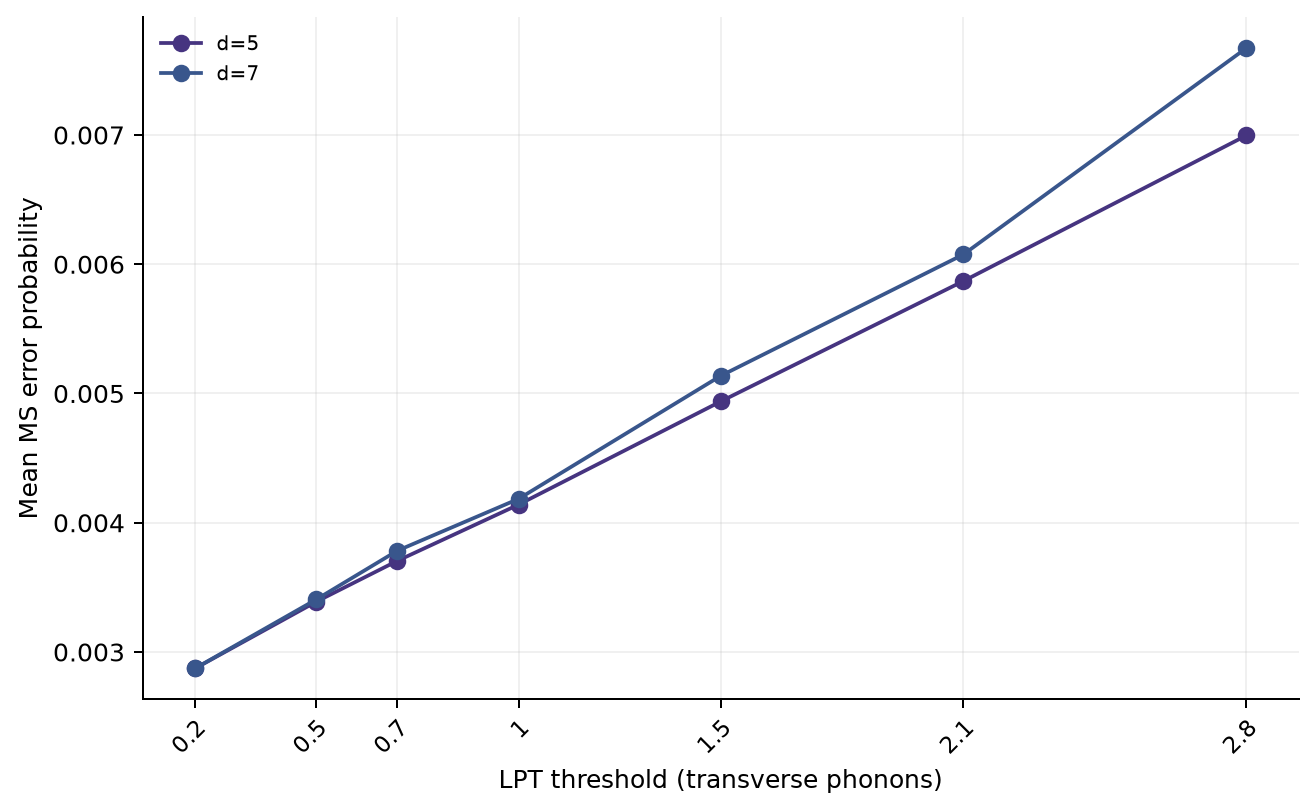

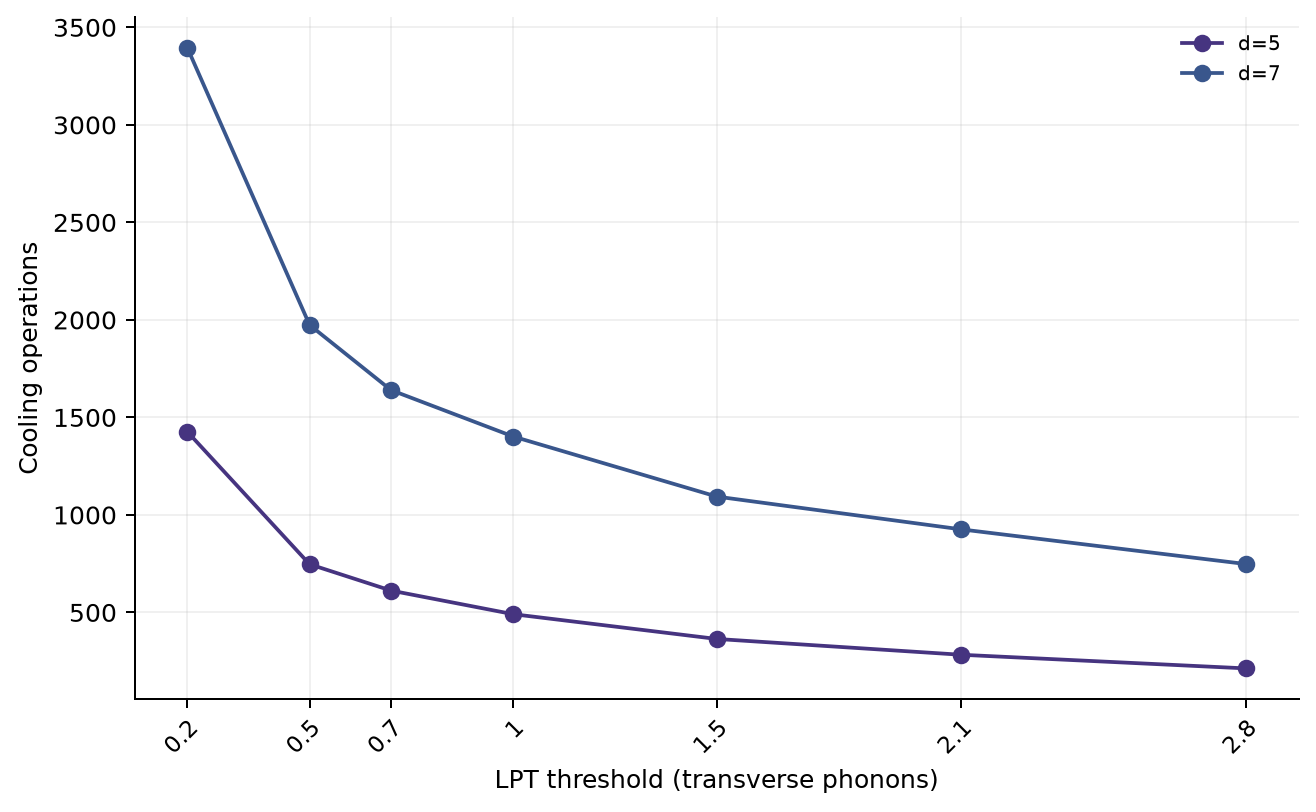

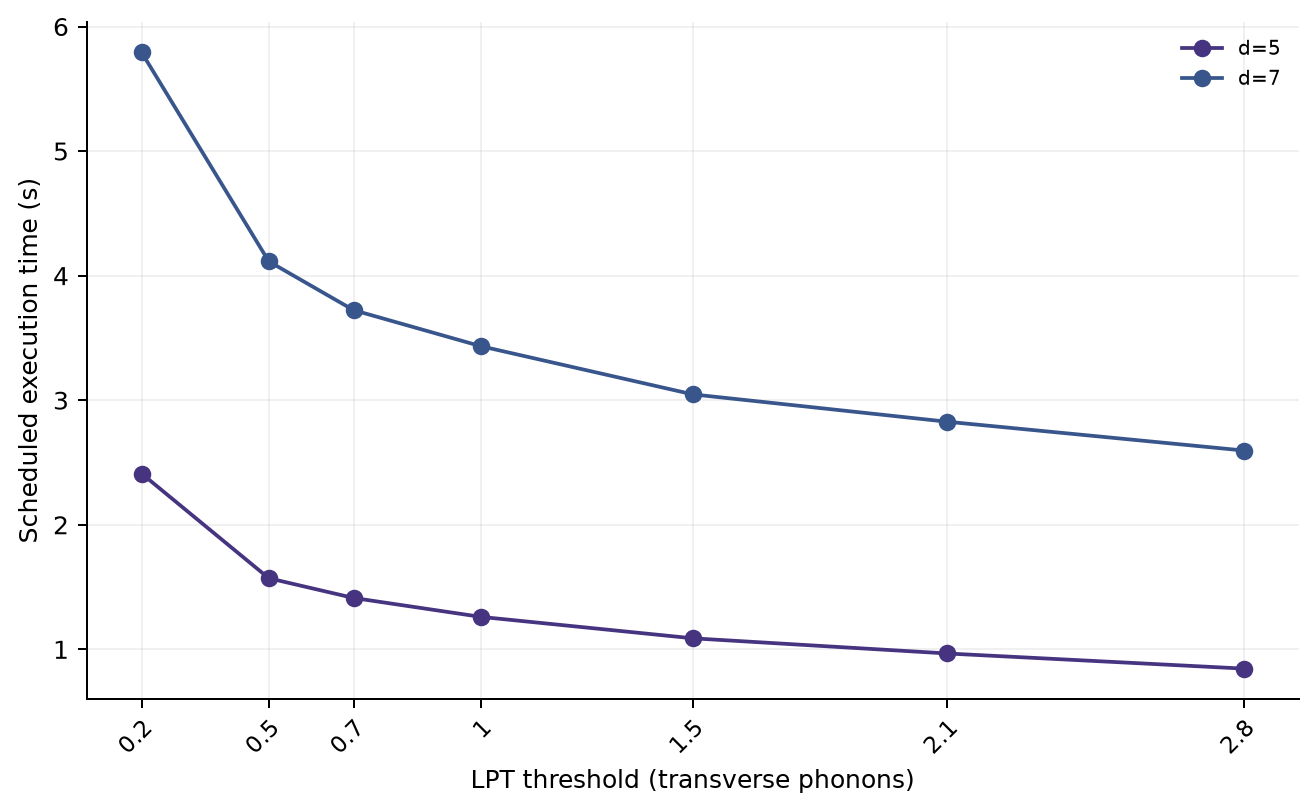

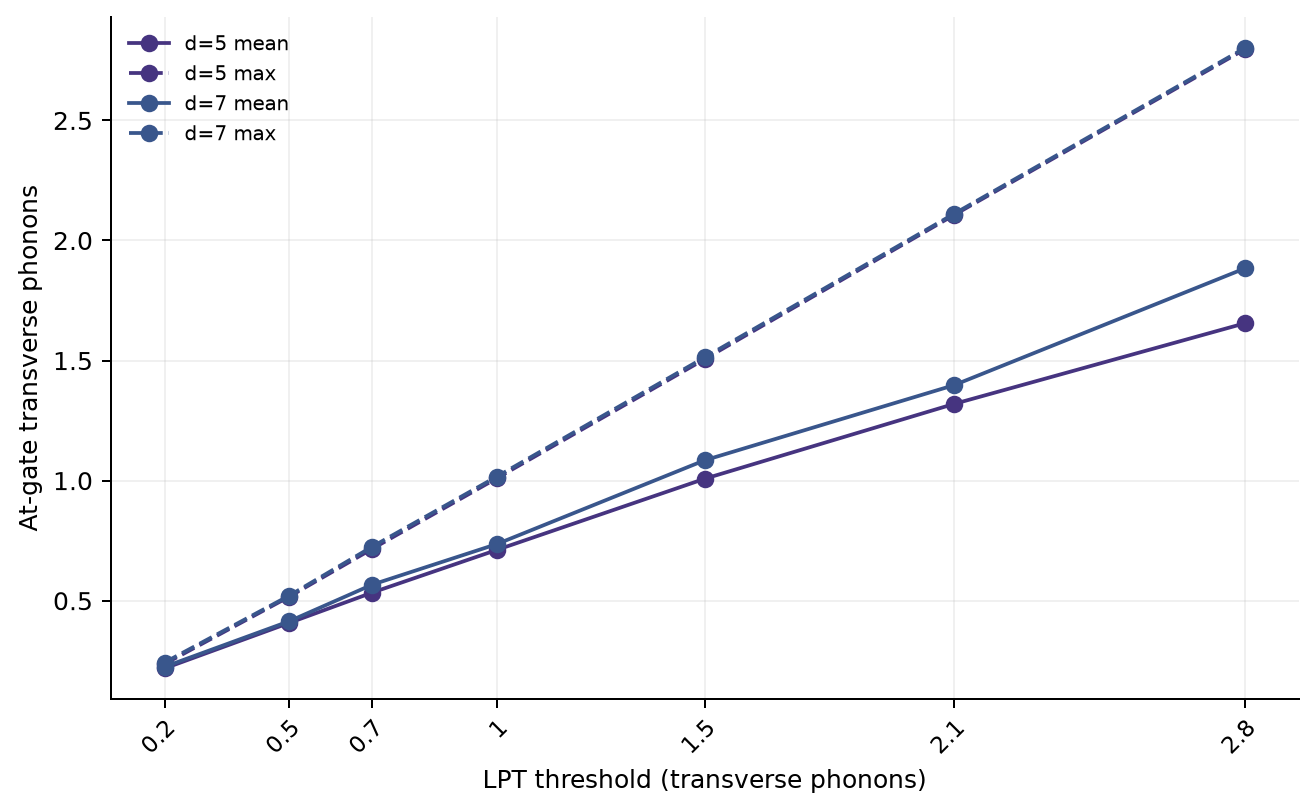

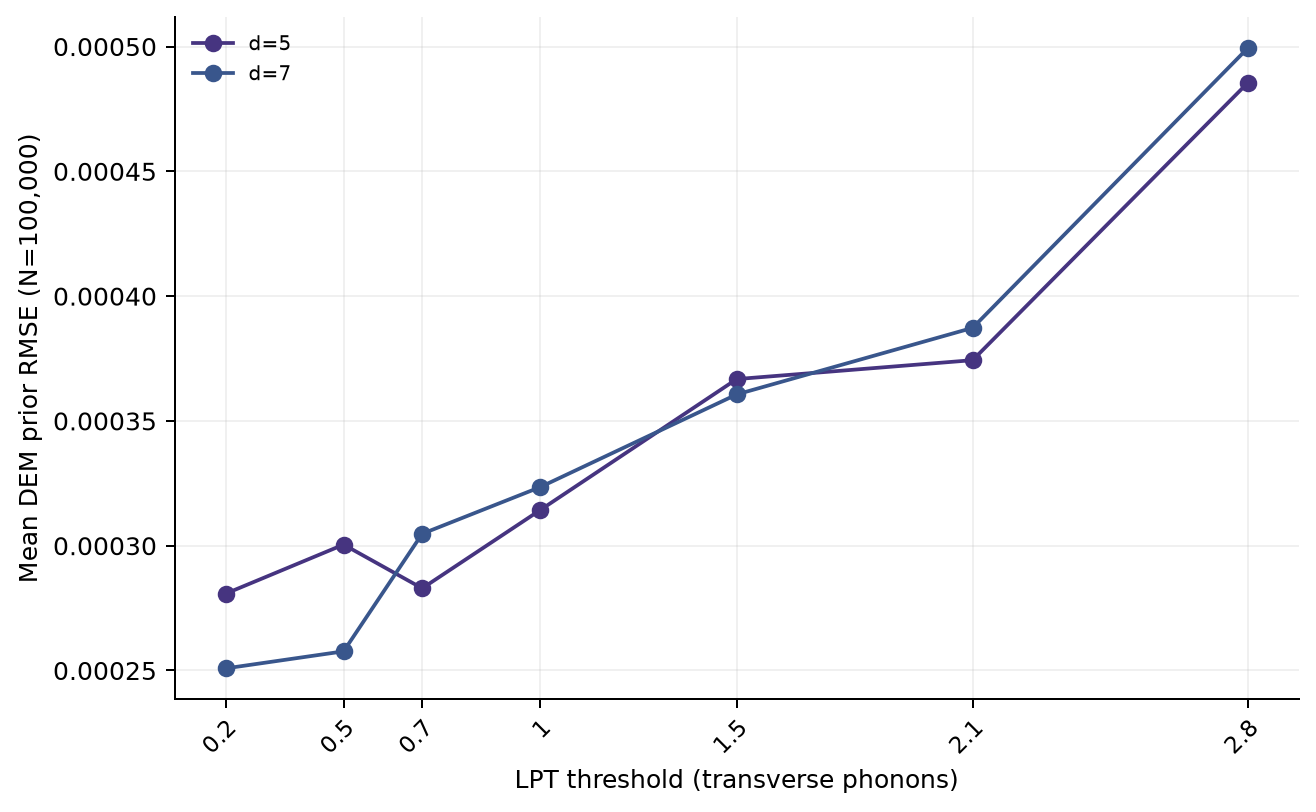

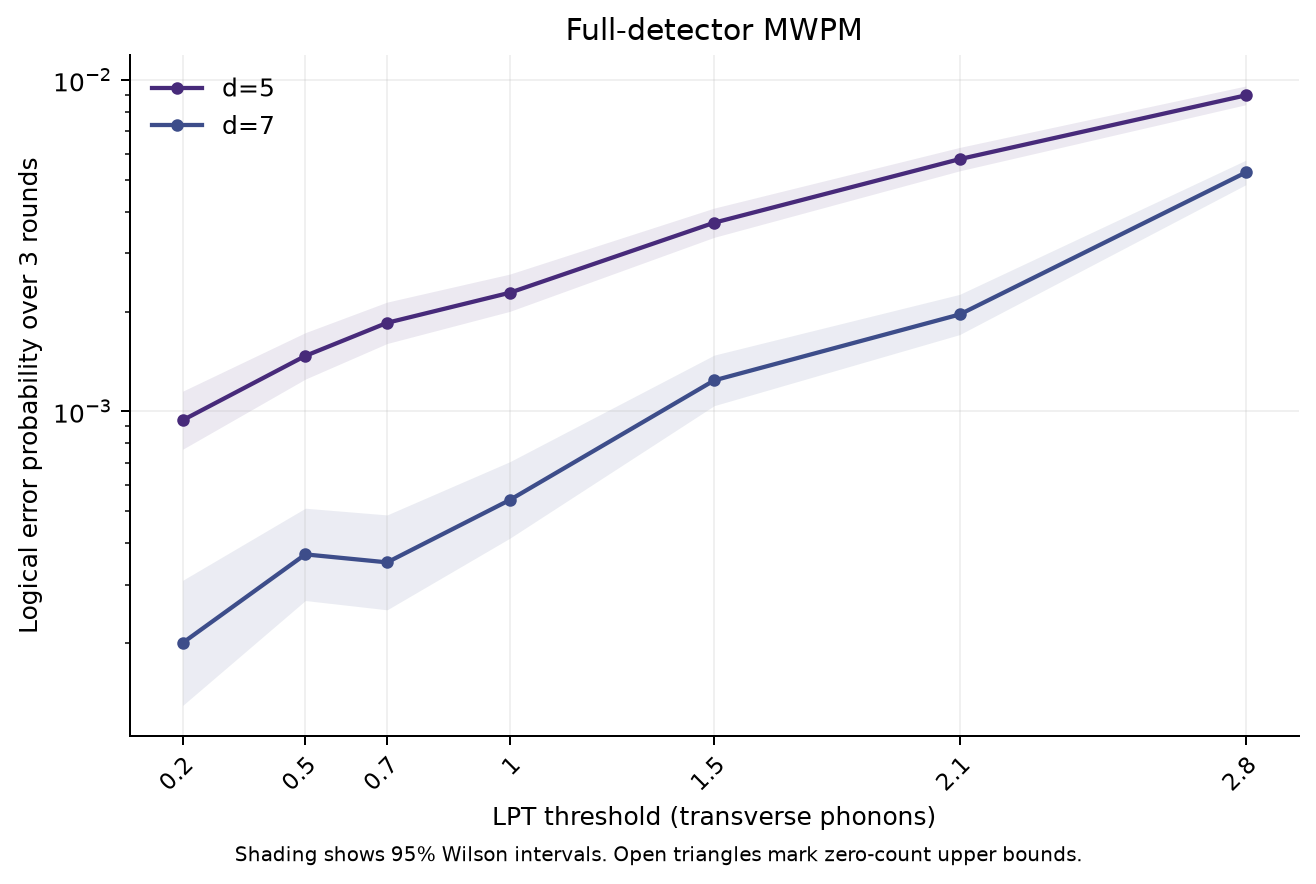

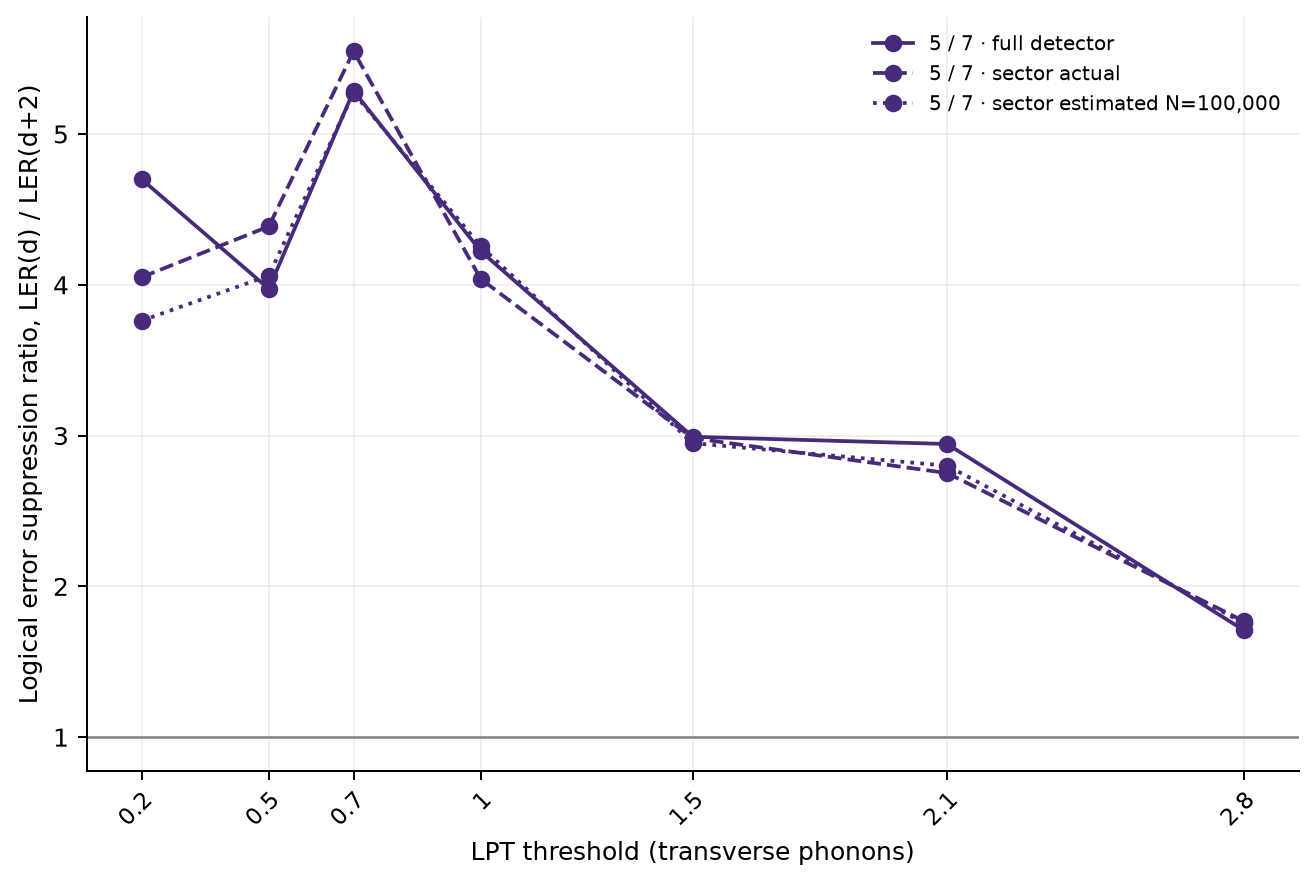

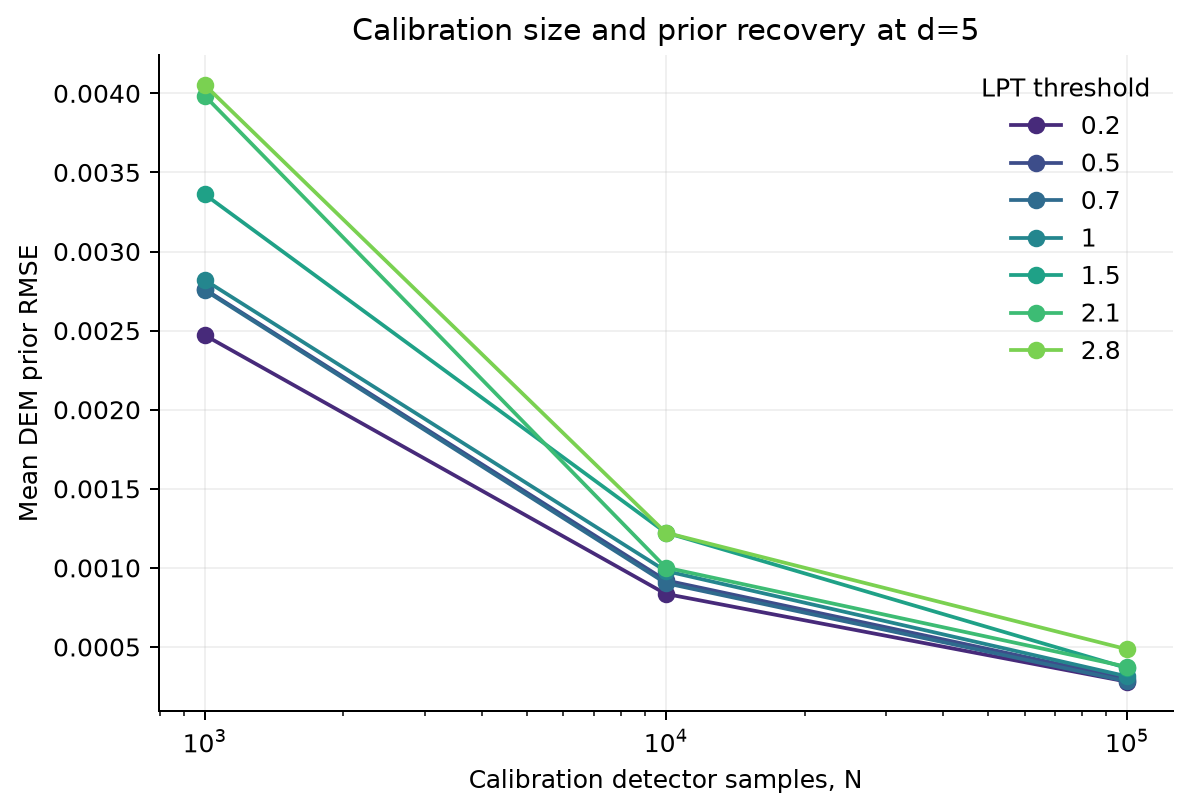

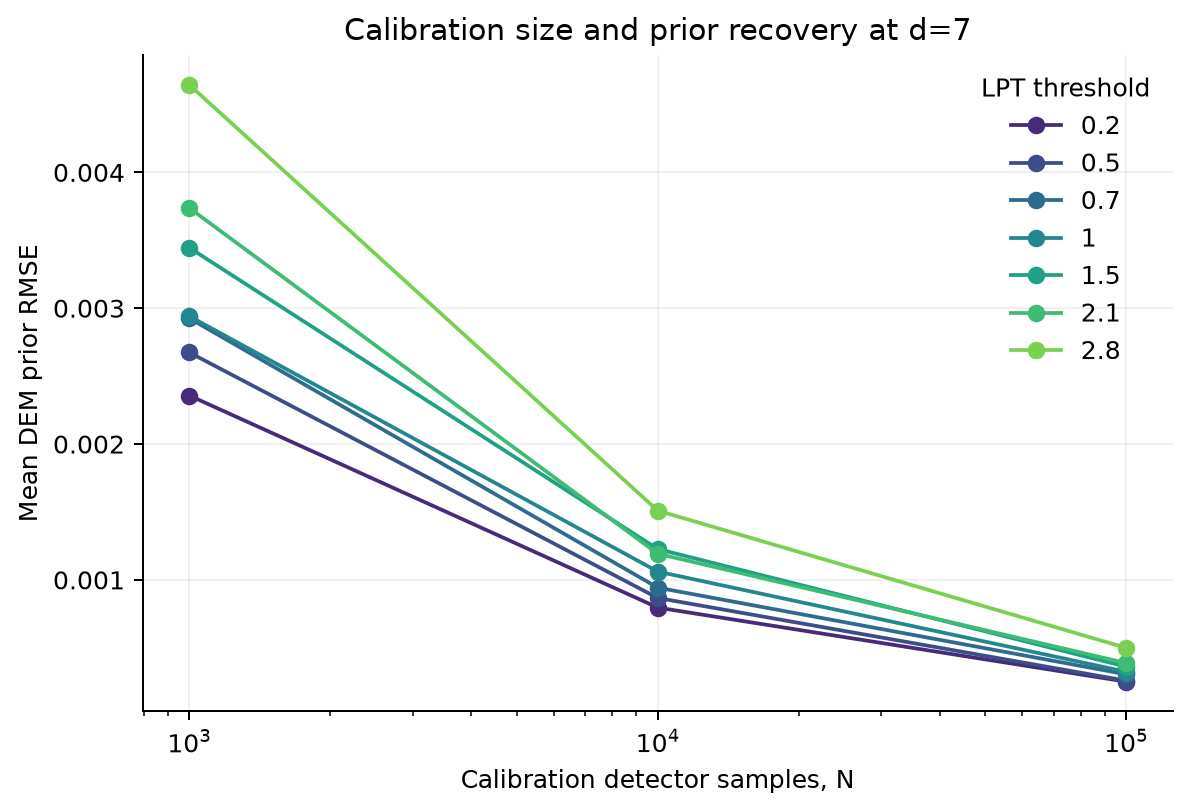

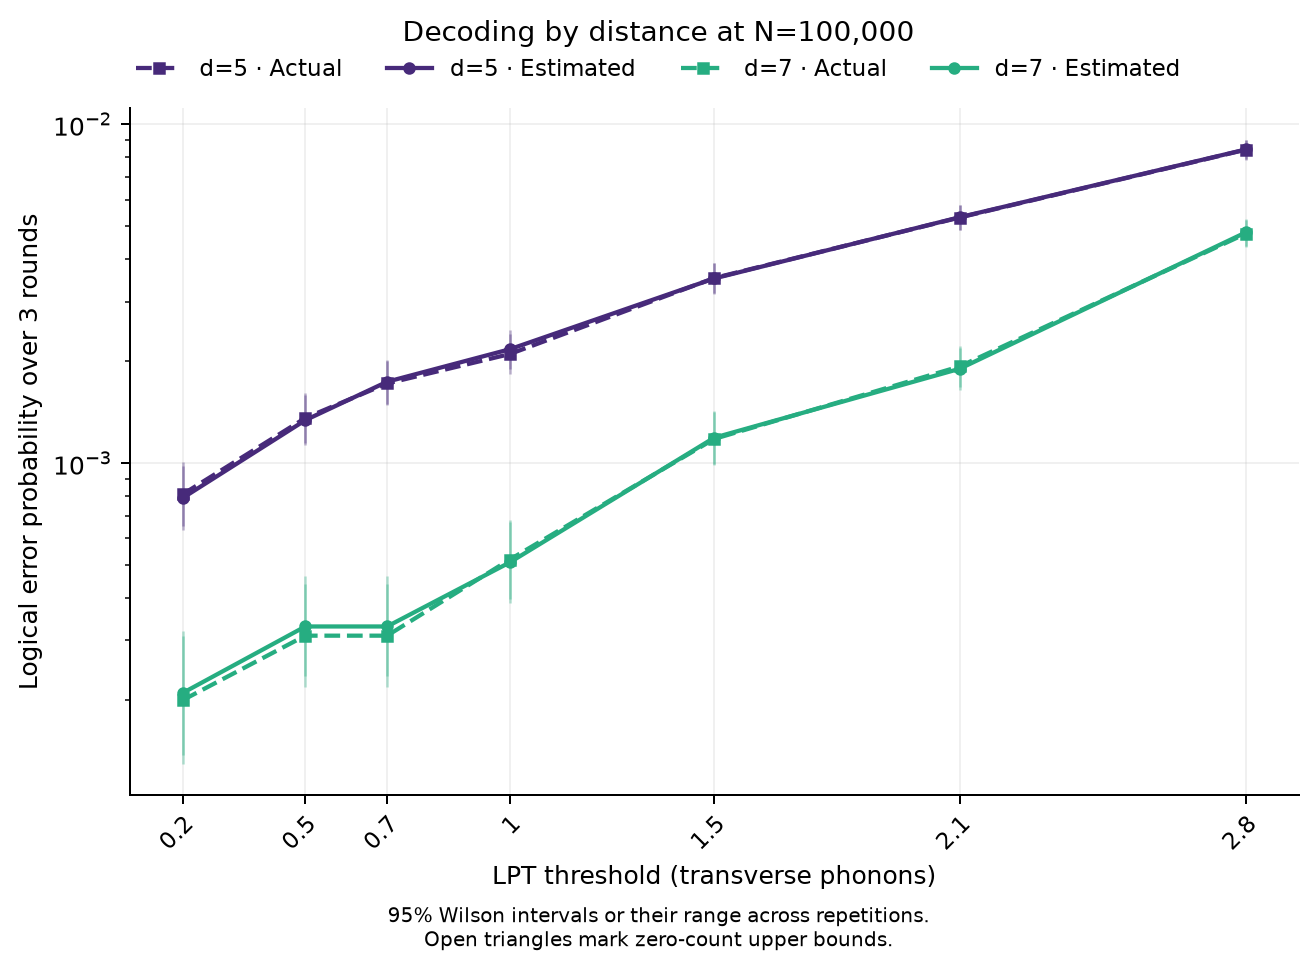

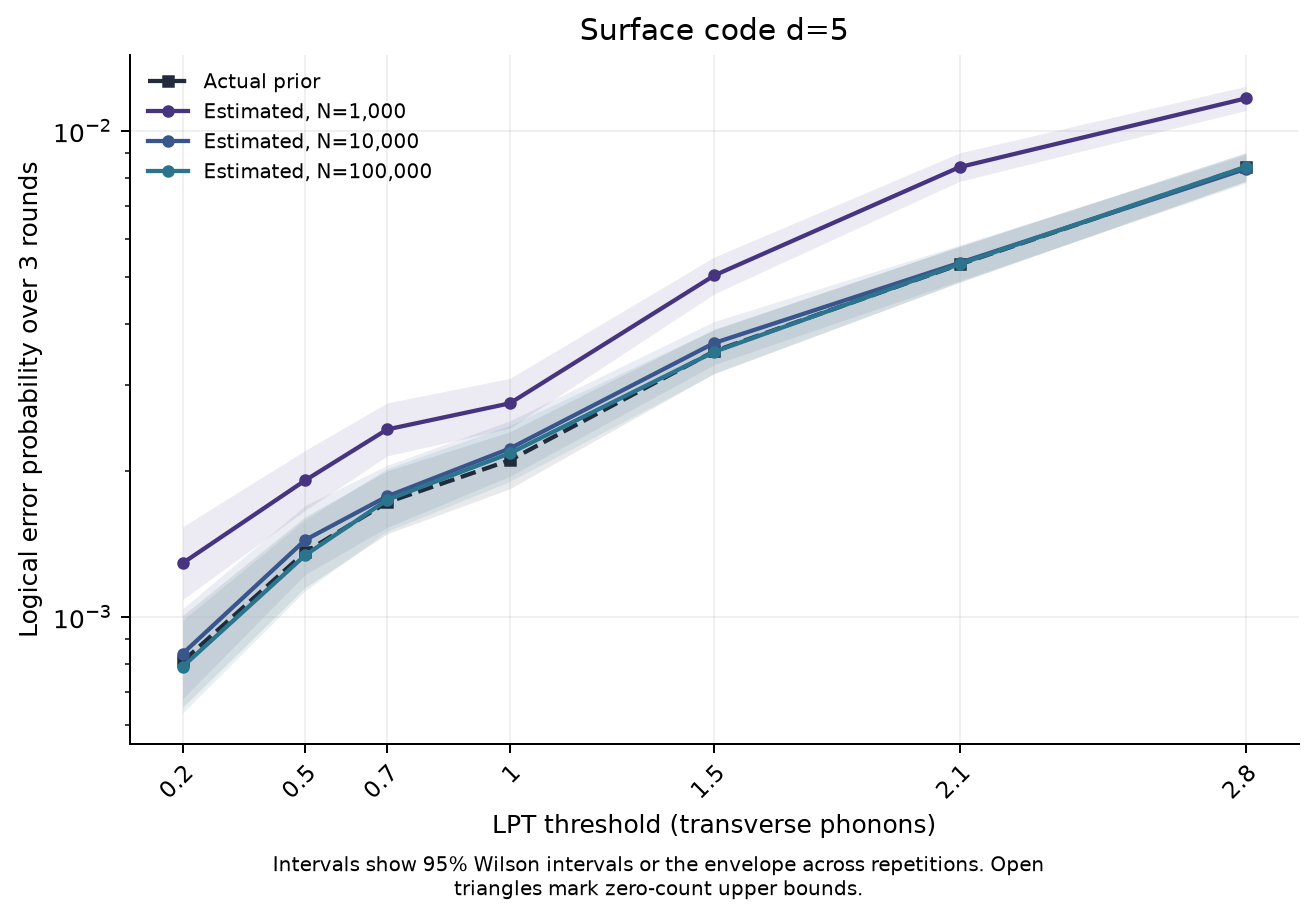

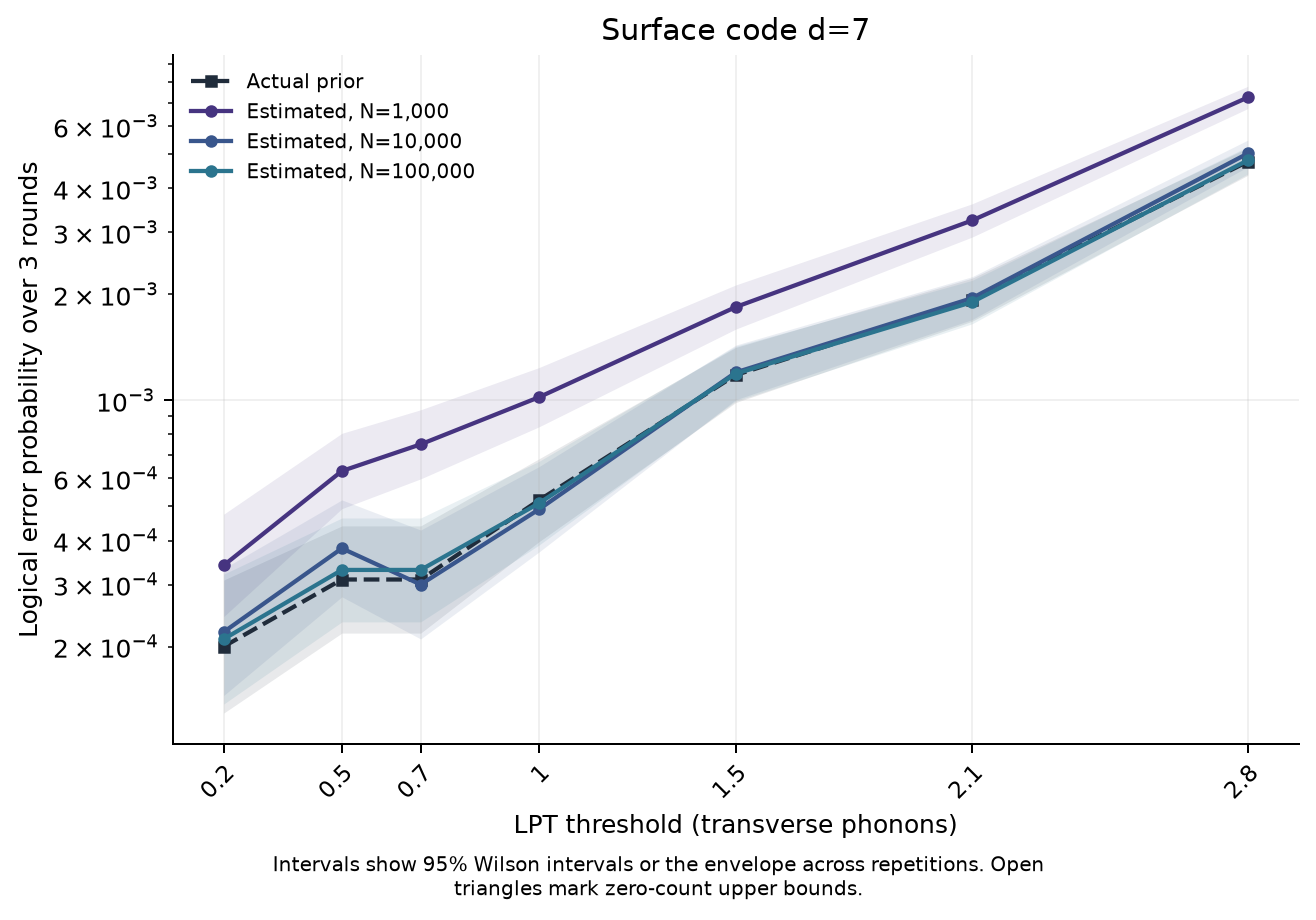

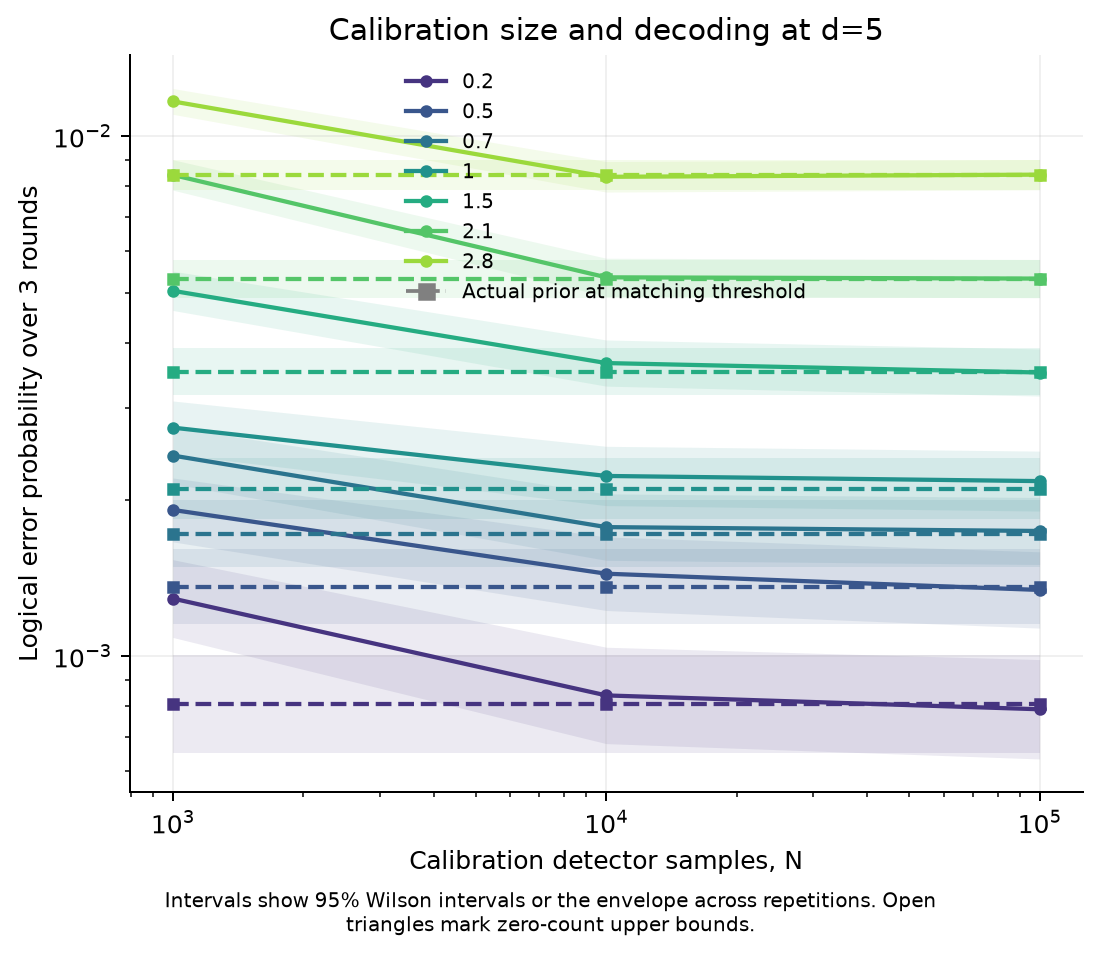

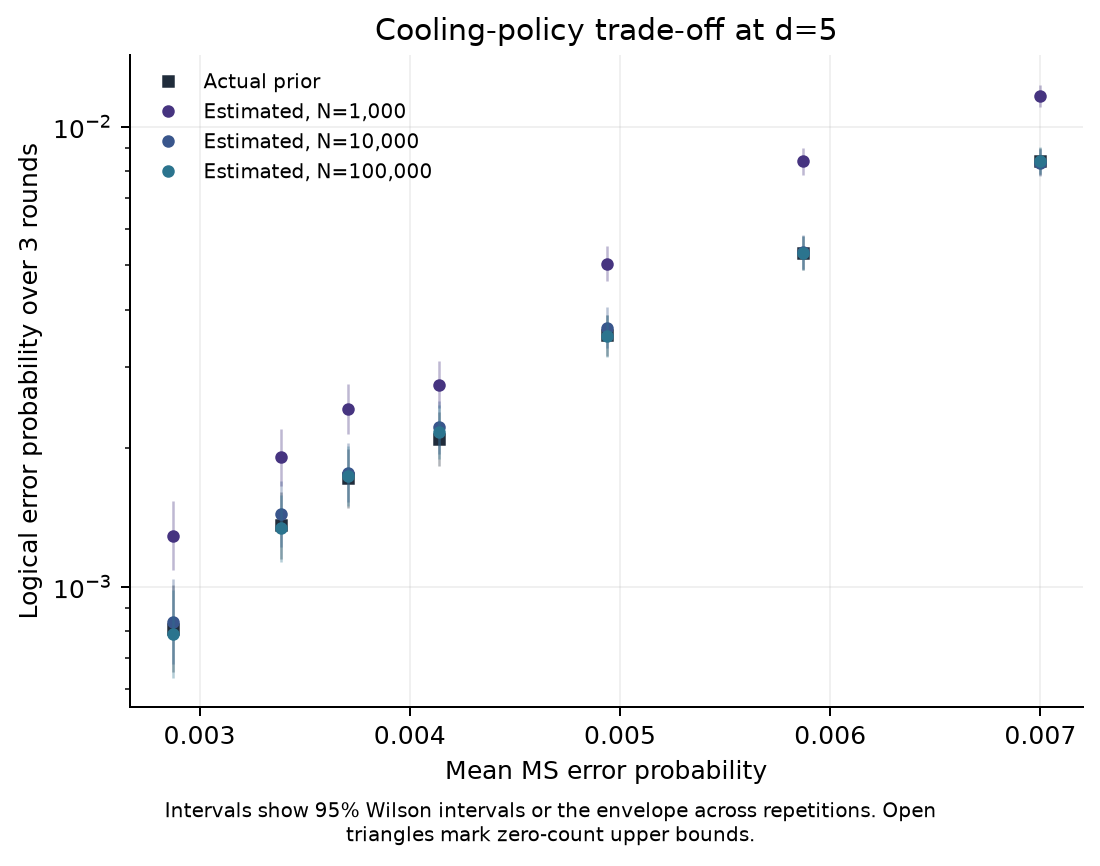

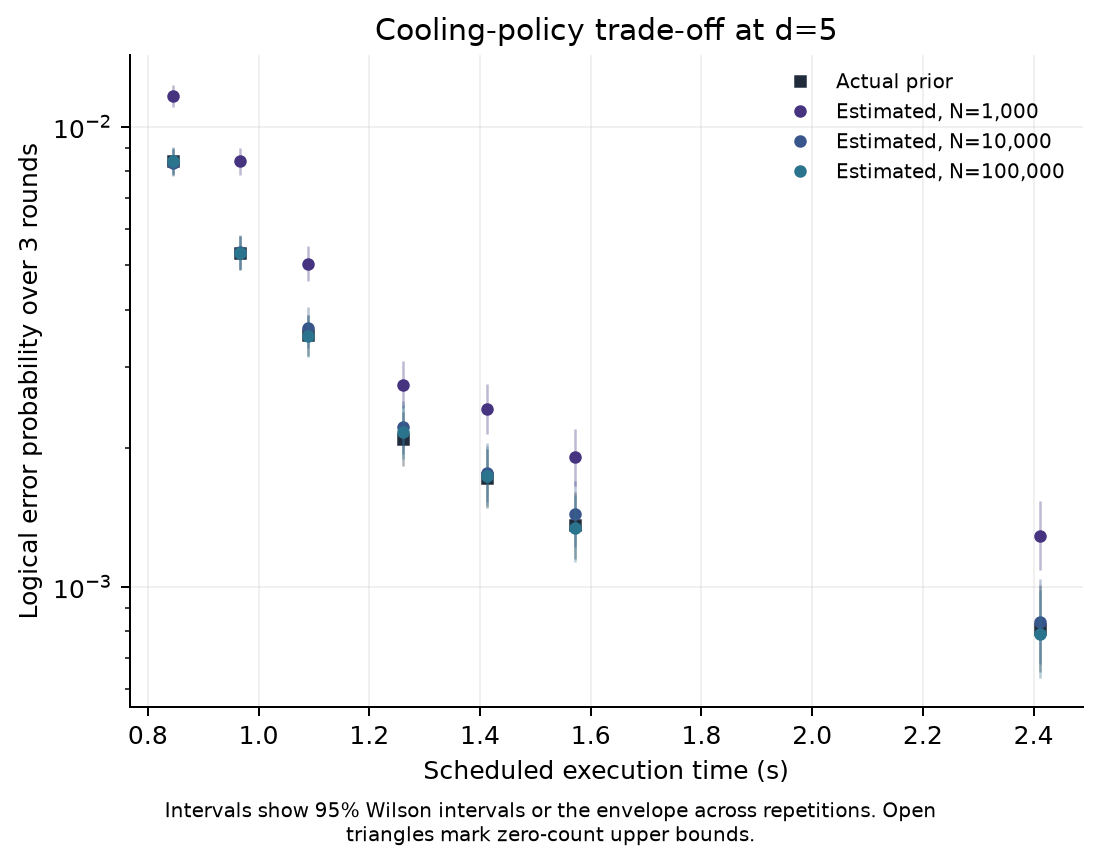

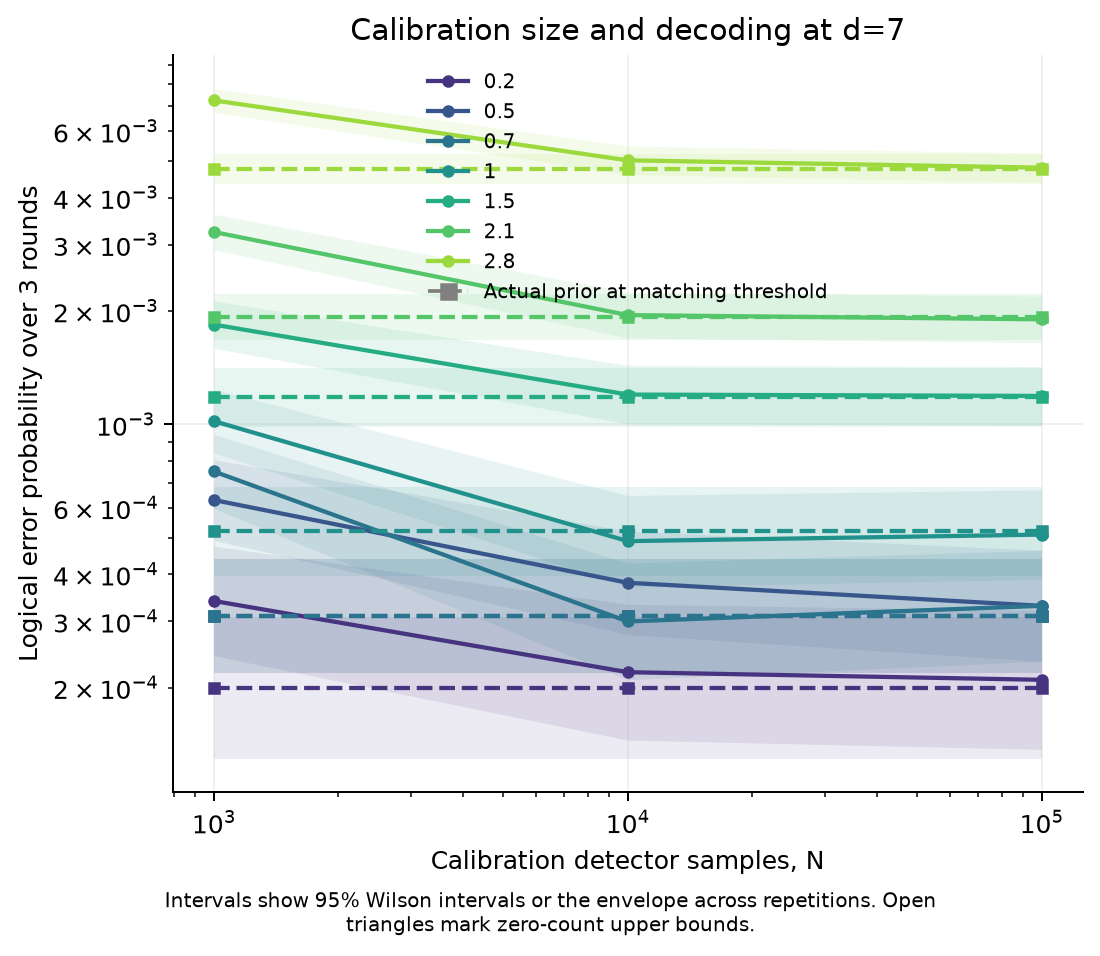

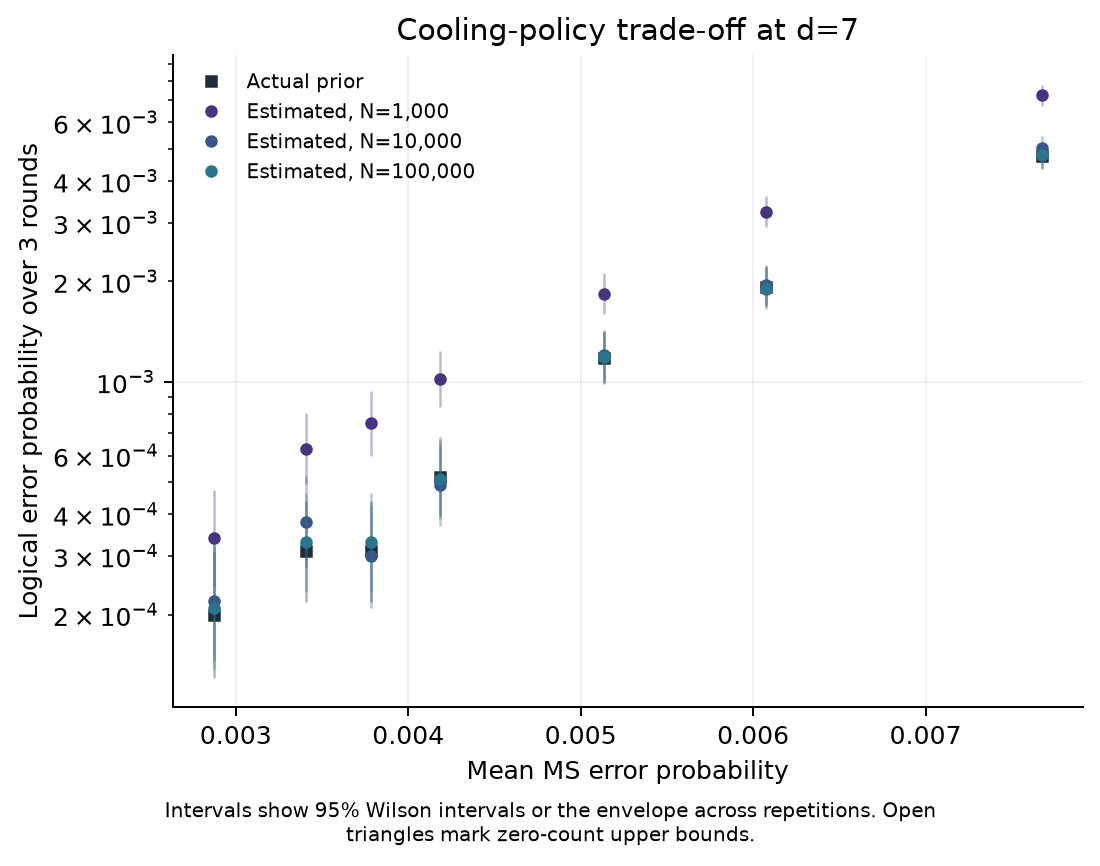

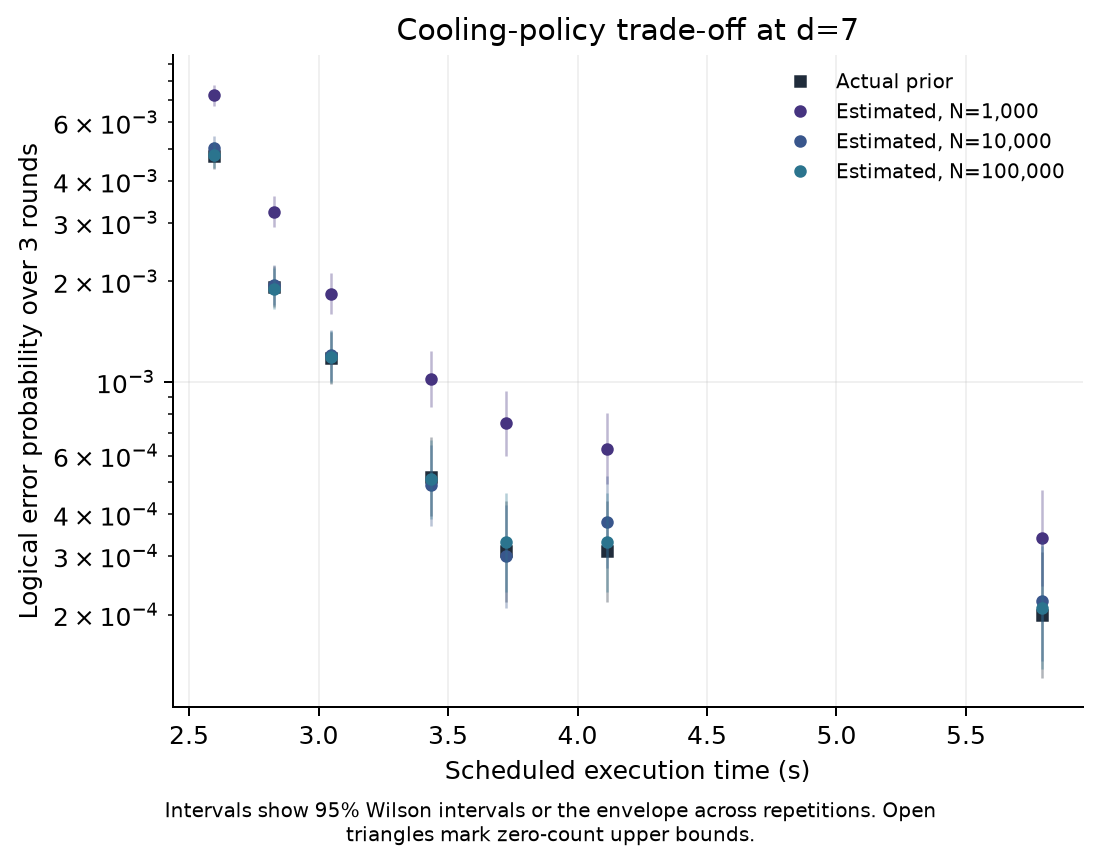

In [6]:
comparison_shots = max(config.training_shots) if LER_COMPARISON_SHOTS is None else LER_COMPARISON_SHOTS
figure_paths = plot_results(OUT, split_ler=True, figure_dir=REPORT / 'figures',
                            comparison_shots=comparison_shots, include_no_cooling=False)
if not read_json(OUT / 'suppression_ratios.json'):
    print('The suppression ratio requires two evaluated distances separated by two.')
from IPython.display import Image
for path in figure_paths:
    if path.suffix == '.png' and not path.name.startswith('priors_'):
        display(Image(filename=str(path)))


## 7. Compare actual and estimated probabilities with RMSE

The raw S11 $p_{ij}$ comparison counts each unique off-diagonal pair once
($i<j$). It retains negative finite estimates and reports coverage for all
pairs and separately for known pair mechanisms. Actual probabilities are
zero at nonedges. Prior RMSE compares the saved regularized decoder priors
against the actual priors in canonical edge order, including both pair and
singleton mechanisms. Each RMSE is the square root of the mean squared
probability difference over the indicated entries.


In [7]:
import csv

metric_keys = ('raw_pair_rmse_all', 'raw_pair_rmse_support', 'prior_rmse',
               'finite_pairs', 'total_pairs', 'finite_known_pairs', 'total_known_pairs', 'mechanisms')
rmse_rows = []
for sweep_case in case_list:
    model = read_json(sweep_case.directory / 'model.json')
    built = (sweep_case.directory / 'known_structure.json').is_file()
    if built:
        structure = GraphStructure.from_dict(read_json(sweep_case.directory / 'known_structure.json'))
        actual = np.load(sweep_case.directory / 'actual_priors.npy', allow_pickle=False)
    for rep in range(config.repetitions):
        for count in config.training_shots:
            folder = fit_directory(sweep_case, rep=rep, shots=count)
            row = dict(distance=sweep_case.distance, rounds=sweep_case.rounds, liz_pt_threshold=sweep_case.cool_threshold,
                       calibration_shots=count, repetition=rep)
            if built and (folder / 'fit_complete.json').is_file():
                estimated = np.load(folder / 'estimated_priors.npy', allow_pickle=False)
                raw_pairs = np.load(folder / 'p_ij.npy', allow_pickle=False)
                row.update(status='ok', **prior_rmse(structure, actual, estimated, raw_pairs))
            else:
                status = 'undefined' if (folder / 'fit_skipped.json').is_file() else 'missing'
                row.update(status=status if built else model['projection_error'], **dict.fromkeys(metric_keys))
            rmse_rows.append(row)

report_csv = REPORT / 'prior_rmse.csv'
REPORT.mkdir(parents=True, exist_ok=True)
with report_csv.open('w', encoding='utf-8', newline='') as file:
    writer = csv.DictWriter(file, fieldnames=list(rmse_rows[0]))
    writer.writeheader()
    writer.writerows(rmse_rows)

def show_rmse(value):
    return f'{value:.6g}' if value is not None else '—'

header = ('| d | LPT threshold | Calibration N | Repetition | Raw p_ij RMSE, all pairs | Finite / all | '
          'Raw p_ij RMSE, known pairs | Finite / known | Prior RMSE | Status |\n'
          '|---|---|---|---|---|---|---|---|---|---|\n')
body = []
for row in rmse_rows:
    all_pairs = (f"{row['finite_pairs']:,} / {row['total_pairs']:,}" if row['status'] == 'ok' else '—')
    known_pairs = (f"{row['finite_known_pairs']:,} / {row['total_known_pairs']:,}" if row['status'] == 'ok' else '—')
    body.append(
        f"| {row['distance']} | {threshold_label(row['liz_pt_threshold'])} | {row['calibration_shots']:,} | {row['repetition']} "
        f"| {show_rmse(row['raw_pair_rmse_all'])} | {all_pairs} | {show_rmse(row['raw_pair_rmse_support'])} "
        f"| {known_pairs} | {show_rmse(row['prior_rmse'])} | {row['status']} |")
display(Markdown(header + '\n'.join(body)))


| d | LPT threshold | Calibration N | Repetition | Raw p_ij RMSE, all pairs | Finite / all | Raw p_ij RMSE, known pairs | Finite / known | Prior RMSE | Status |
|---|---|---|---|---|---|---|---|---|---|
| 5 | 0.2 | 1,000 | 0 | 0.00127668 | 1,128 / 1,128 | 0.00228369 | 165 / 165 | 0.0024713 | ok |
| 5 | 0.2 | 10,000 | 0 | 0.000428682 | 1,128 / 1,128 | 0.000790739 | 165 / 165 | 0.000835657 | ok |
| 5 | 0.2 | 100,000 | 0 | 0.000126583 | 1,128 / 1,128 | 0.000219046 | 165 / 165 | 0.000280773 | ok |
| 5 | 0.5 | 1,000 | 0 | 0.00149512 | 1,128 / 1,128 | 0.00249544 | 165 / 165 | 0.00276161 | ok |
| 5 | 0.5 | 10,000 | 0 | 0.000465359 | 1,128 / 1,128 | 0.000809292 | 165 / 165 | 0.000921004 | ok |
| 5 | 0.5 | 100,000 | 0 | 0.000143436 | 1,128 / 1,128 | 0.000249827 | 165 / 165 | 0.00030044 | ok |
| 5 | 0.7 | 1,000 | 0 | 0.00149619 | 1,128 / 1,128 | 0.00245491 | 165 / 165 | 0.00275609 | ok |
| 5 | 0.7 | 10,000 | 0 | 0.000487722 | 1,128 / 1,128 | 0.000807926 | 165 / 165 | 0.000903513 | ok |
| 5 | 0.7 | 100,000 | 0 | 0.000145839 | 1,128 / 1,128 | 0.000250581 | 165 / 165 | 0.000282919 | ok |
| 5 | 1 | 1,000 | 0 | 0.00170401 | 1,128 / 1,128 | 0.00271565 | 165 / 165 | 0.00282034 | ok |
| 5 | 1 | 10,000 | 0 | 0.000527783 | 1,128 / 1,128 | 0.000860012 | 165 / 165 | 0.000980374 | ok |
| 5 | 1 | 100,000 | 0 | 0.000172169 | 1,128 / 1,128 | 0.000293483 | 165 / 165 | 0.000314268 | ok |
| 5 | 1.5 | 1,000 | 0 | 0.00196986 | 1,128 / 1,128 | 0.00307251 | 165 / 165 | 0.00336174 | ok |
| 5 | 1.5 | 10,000 | 0 | 0.000598703 | 1,128 / 1,128 | 0.000993972 | 165 / 165 | 0.00122309 | ok |
| 5 | 1.5 | 100,000 | 0 | 0.000189576 | 1,128 / 1,128 | 0.000306796 | 165 / 165 | 0.000366763 | ok |
| 5 | 2.1 | 1,000 | 0 | 0.00225566 | 1,128 / 1,128 | 0.00355974 | 165 / 165 | 0.00398511 | ok |
| 5 | 2.1 | 10,000 | 0 | 0.000689726 | 1,128 / 1,128 | 0.000987097 | 165 / 165 | 0.00100215 | ok |
| 5 | 2.1 | 100,000 | 0 | 0.000212969 | 1,128 / 1,128 | 0.000326712 | 165 / 165 | 0.000374338 | ok |
| 5 | 2.8 | 1,000 | 0 | 0.00272524 | 1,128 / 1,128 | 0.00390795 | 165 / 165 | 0.00405358 | ok |
| 5 | 2.8 | 10,000 | 0 | 0.000752336 | 1,128 / 1,128 | 0.00110819 | 165 / 165 | 0.00122253 | ok |
| 5 | 2.8 | 100,000 | 0 | 0.00024968 | 1,128 / 1,128 | 0.000380323 | 165 / 165 | 0.000485504 | ok |
| 7 | 0.2 | 1,000 | 0 | 0.00126414 | 4,560 / 4,560 | 0.00229237 | 371 / 371 | 0.00235685 | ok |
| 7 | 0.2 | 10,000 | 0 | 0.000400221 | 4,560 / 4,560 | 0.000738618 | 371 / 371 | 0.000795914 | ok |
| 7 | 0.2 | 100,000 | 0 | 0.000128603 | 4,560 / 4,560 | 0.000242141 | 371 / 371 | 0.000250835 | ok |
| 7 | 0.5 | 1,000 | 0 | 0.0013556 | 4,560 / 4,560 | 0.00248524 | 371 / 371 | 0.00267393 | ok |
| 7 | 0.5 | 10,000 | 0 | 0.000449226 | 4,560 / 4,560 | 0.000797019 | 371 / 371 | 0.000866764 | ok |
| 7 | 0.5 | 100,000 | 0 | 0.000139961 | 4,560 / 4,560 | 0.000239878 | 371 / 371 | 0.000257666 | ok |
| 7 | 0.7 | 1,000 | 0 | 0.00153281 | 4,560 / 4,560 | 0.0028013 | 371 / 371 | 0.00292582 | ok |
| 7 | 0.7 | 10,000 | 0 | 0.00050185 | 4,560 / 4,560 | 0.000862048 | 371 / 371 | 0.000942803 | ok |
| 7 | 0.7 | 100,000 | 0 | 0.000159174 | 4,560 / 4,560 | 0.000283311 | 371 / 371 | 0.000304776 | ok |
| 7 | 1 | 1,000 | 0 | 0.00168376 | 4,560 / 4,560 | 0.00288949 | 371 / 371 | 0.00294074 | ok |
| 7 | 1 | 10,000 | 0 | 0.000544835 | 4,560 / 4,560 | 0.000929666 | 371 / 371 | 0.00106115 | ok |
| 7 | 1 | 100,000 | 0 | 0.000170916 | 4,560 / 4,560 | 0.000289596 | 371 / 371 | 0.000323469 | ok |
| 7 | 1.5 | 1,000 | 0 | 0.00198161 | 4,560 / 4,560 | 0.00304334 | 371 / 371 | 0.00344499 | ok |
| 7 | 1.5 | 10,000 | 0 | 0.000639903 | 4,560 / 4,560 | 0.00103559 | 371 / 371 | 0.00122694 | ok |
| 7 | 1.5 | 100,000 | 0 | 0.000204306 | 4,560 / 4,560 | 0.000324221 | 371 / 371 | 0.000360619 | ok |
| 7 | 2.1 | 1,000 | 0 | 0.00236357 | 4,560 / 4,560 | 0.00376198 | 371 / 371 | 0.00373746 | ok |
| 7 | 2.1 | 10,000 | 0 | 0.000763962 | 4,560 / 4,560 | 0.00112266 | 371 / 371 | 0.00119258 | ok |
| 7 | 2.1 | 100,000 | 0 | 0.000241956 | 4,560 / 4,560 | 0.000371323 | 371 / 371 | 0.000387285 | ok |
| 7 | 2.8 | 1,000 | 0 | 0.00319282 | 4,560 / 4,560 | 0.00448929 | 371 / 371 | 0.00464417 | ok |
| 7 | 2.8 | 10,000 | 0 | 0.000936555 | 4,560 / 4,560 | 0.00137093 | 371 / 371 | 0.00150986 | ok |
| 7 | 2.8 | 100,000 | 0 | 0.000301957 | 4,560 / 4,560 | 0.000452045 | 371 / 371 | 0.000499408 | ok |

## 8. Inspect recovered priors and saved artifacts

The first two panels compare the actual pair-probability matrix and raw S11
matrix. The third compares pair and boundary priors. Negative raw estimates
remain visible in the raw matrix; floor-clipped decoder probabilities appear
on the floor line in the scatter plot. True priors are accessed only for this
post-fit comparison.


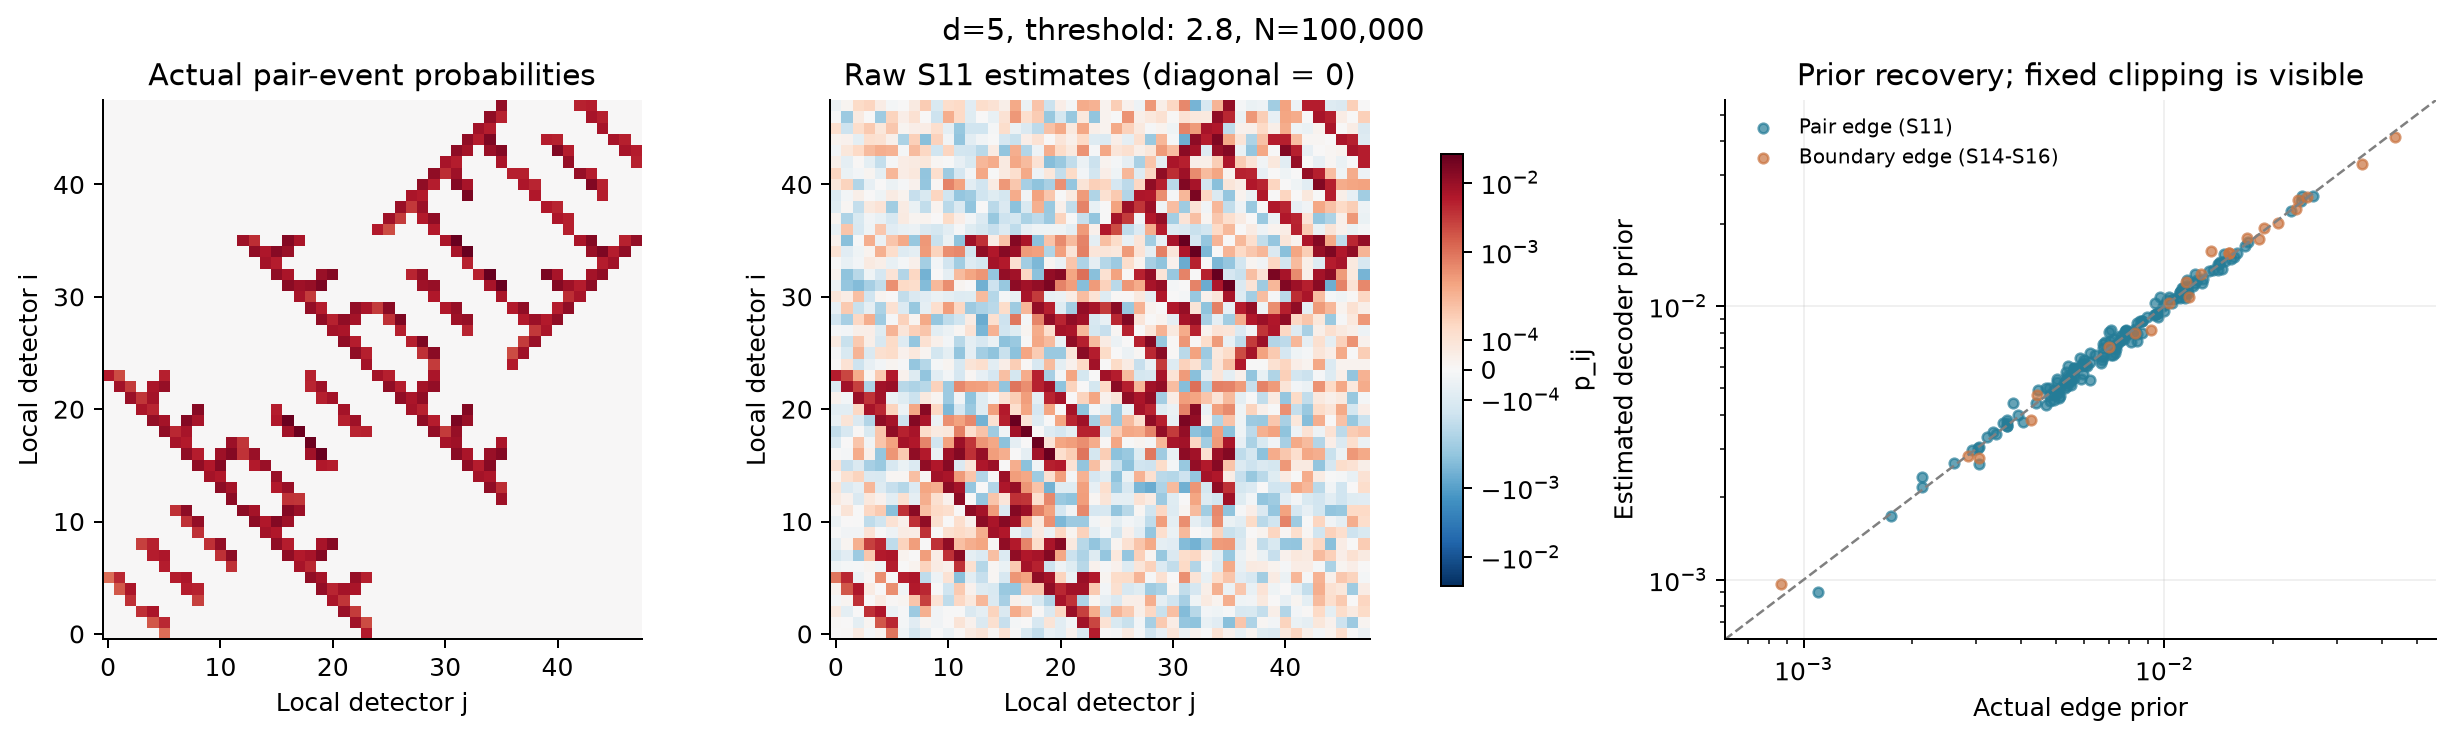

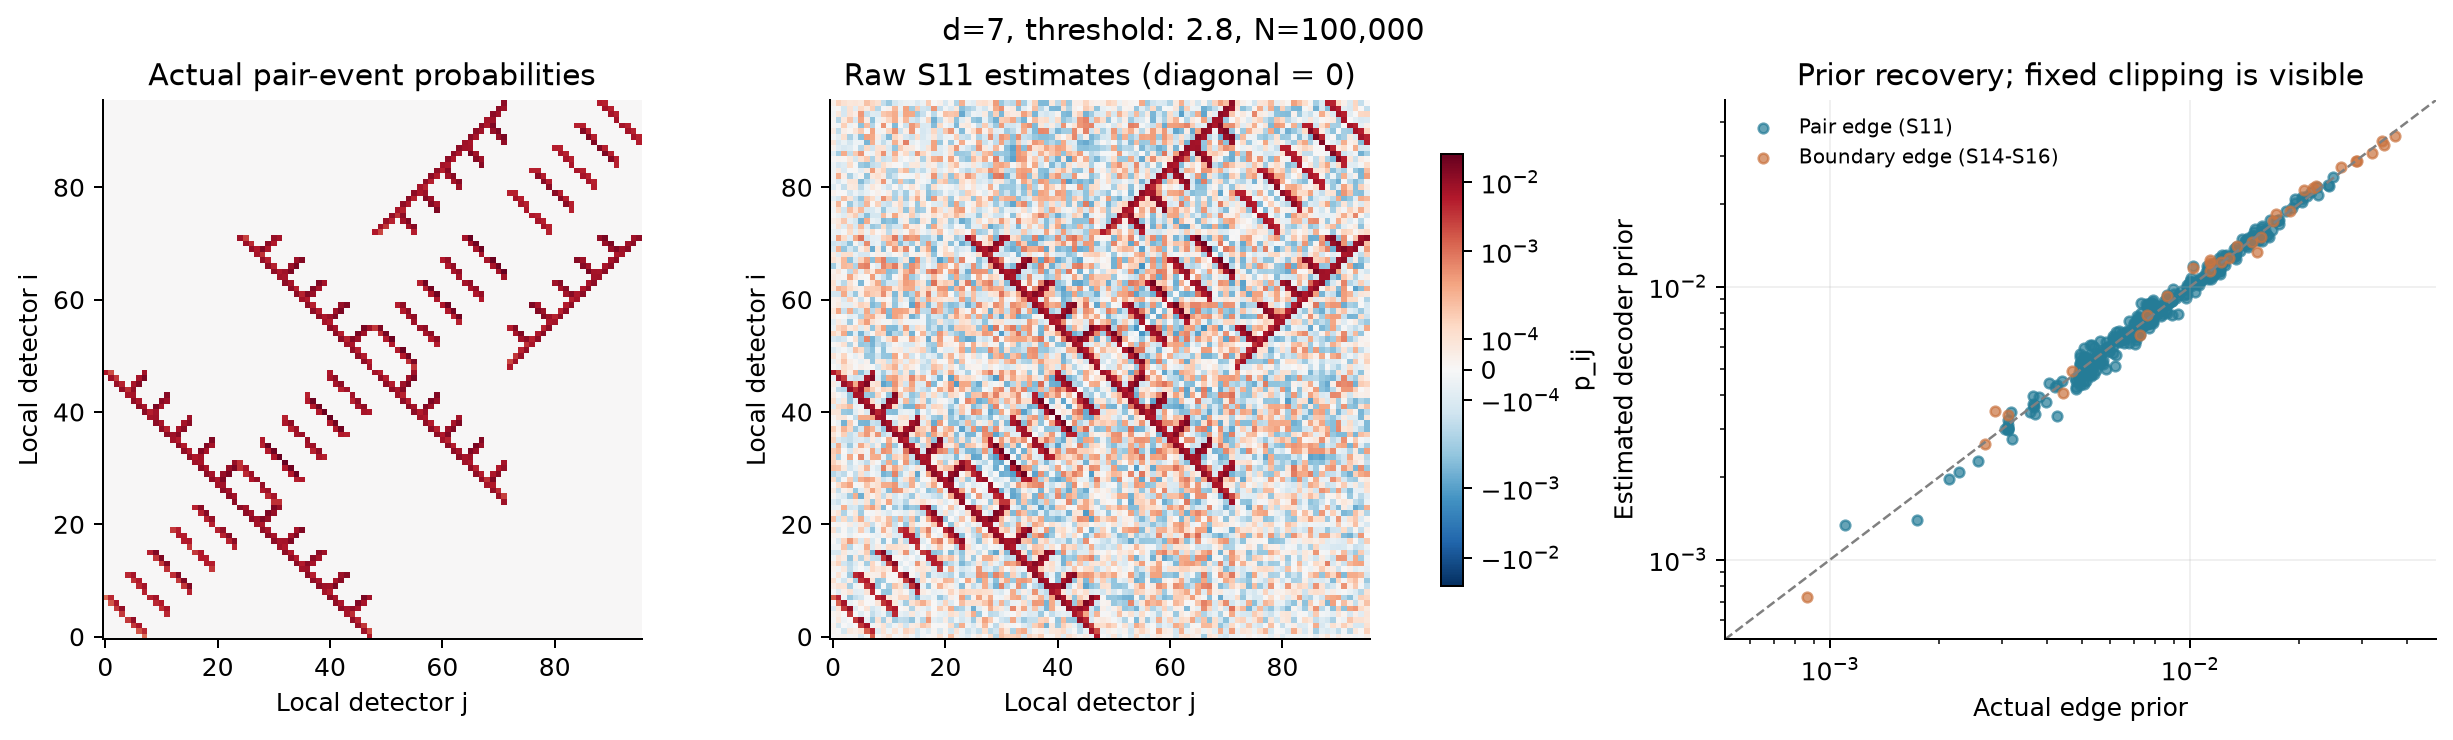

Prior error diagnostics: {'mean_absolute_error': 0.0003725103788550159, 'root_mean_squared_error': 0.0004994082487095753, 'max_absolute_error': 0.0019241625550526914, 'num_edges': 403}
Loaded experiment: /home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/results/lpt_calibration
RMSE table: /home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/results/lpt_calibration/walkthrough/prior_rmse.csv
Standalone figures: /home/quantum_teresheys/workspace/HEM3/theata-prior-calibration/results/lpt_calibration/walkthrough/figures


In [8]:
for prior_figure in figure_paths:
    if prior_figure.suffix == '.png' and prior_figure.name.startswith('priors_'):
        display(Image(filename=str(prior_figure)))
if fit_dir is not None and (fit_dir / 'prior_error.json').is_file():
    print('Prior error diagnostics:', read_json(fit_dir / 'prior_error.json'))
print('Loaded experiment:', OUT)
print('RMSE table:', report_csv)
print('Standalone figures:', REPORT / 'figures')
